<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_final_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Main Code

In [4]:
# @title 1. SETUP & CONFIGURATION
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, userdata

# 1. MOUNT & DIRECTORIES
drive.mount("/content/drive")
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. GLOBAL STUDY PARAMETERS
REGIONS = ["PJME","COMED"]              # Region for study
#REGIONS = ["PJME", "COMED", "AEP", "DAYTON", "DOM"]
AI_LOAD_LEVELS = [0.10, 0.20, 0.30]     # High load level to ensure visible impact
N_TRIALS = 30                           # High trials for statistical robustness
HORIZON_HOURS = 48                      # 48h window for job flexibility
PLANT_SIZE_MW = 500.0                   # Benchmark for "Plants Saved" metric
DROUGHT_FACTOR = 1.0                    # 1.0 = Normal, 1.2+ = Drought
RHO = 0.15

# 3. PARETO & SOLVER SETTINGS
# Use Log-scale weights to ensure the solver reacts to water
PARETO_WEIGHTS = [0.0, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# "Stressor" Constants to force the Gas vs. Water trade-off
# 0.8 to 0.9	Robust Grid: The grid is strong and has plenty of spare capacity.
# 0.5 Stressed Grid: This simulates a "Peak Day" scenario where existing clean energy is pushed to its limit.
# 0.2 to 0.3	Emergency/Crisis: The grid has very little baseload capacity available.
STRESS_ALPHA = 0.6               # 60% base capacity forces Gas use


IMPORT_LIMIT_MW = 5000.0         # Grid interconnections
SLACK_REGIME = "tight"           # "tight": (1-4h) | "medium": (6-12h) | "loose": (12-24h) window for job movement

# 4. KAGGLE CREDENTIALS
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded securely.")
except Exception:
    print("Warning: Kaggle credentials not found in Secrets.")

print(f"Setup Complete. Results will save to: {RESULTS_FILE}")

Mounted at /content/drive
Kaggle credentials loaded securely.
Setup Complete. Results will save to: final_scientific_results_optimized.csv


In [ ]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
import shutil
import zipfile

def download_data_if_missing():
#     # A. Grid Load (Kaggle)
#     if not os.listdir(HOURLY_LOAD_DIR):
#         print("Downloading Grid Load Data from Kaggle...")
#         # Secure system call using the directory from configuration
#         os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
#         zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")

#         if os.path.exists(zip_path):
#             with zipfile.ZipFile(zip_path, 'r') as z:
#                 z.extractall(HOURLY_LOAD_DIR)
#             print("Grid Data Extracted to hourly_load_raw.")
#         else:
#             print("Error: Zip file from Kaggle not found. Check credentials.")

    # B. Water Data (HydroShare / Manual)
    # We move the CSV into the specific sub-folder defined in Cell 1
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(WATER_IMPACT_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        # Check if it was accidentally downloaded to the BASE_DIR instead of WATER_IMPACT_DIR
        misplaced_path = os.path.join(BASE_DIR, water_csv_name)
        if os.path.exists(misplaced_path):
            print("Moving Water CSV to correct sub-directory...")
            shutil.move(misplaced_path, water_csv_path)
        else:
            print(f"CRITICAL: {water_csv_name} not found in {WATER_IMPACT_DIR}.")
            print("Please upload this file to your Drive folder manually to continue.")
    else:
        print("Water IMPACT Data verified in directory.")

download_data_if_missing()

Water IMPACT Data verified in directory.


In [19]:
# @title 3. DATA LOADERS
import pandas as pd
import numpy as np
import os
from datetime import timedelta

def load_ba_load(region: str):
    """Loads Grid Load with explicit cleaning and reindexing."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Parse and rename
    df = pd.read_csv(path, parse_dates=["Datetime"])
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if not mw_col:
        raise ValueError(f"No *_MW column found in {path}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Clean indices and deduplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to full hourly timeline (fixed 'h' frequency)
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)

    # Clean outliers and fill gaps
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan
    lo, hi = df["load_MW"].quantile(0.001), df["load_MW"].quantile(0.999)
    df["load_MW"] = df["load_MW"].clip(lo, hi).interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """Loads Water Data mapped to BA regions."""
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    # Path check aligned with refined Setup
    path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter and process BA-specific water intensity
    ba_col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[ba_col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Units: l/kWh to m3/MWh (1:1 conversion)
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Final cleaning and resampling (fixed 'h' frequency)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df_clean = df[["w_m3_per_MWh"]].clip(0, hi).resample("h").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours, top_k_candidates=50):
    """Extracts a high-load peak window for regional study."""
    print(f"   -> Extracting Peak {horizon_hours}h Window...")

    # Helper to ensure windows don't overlap too much
    def _dedupe_candidates(times, sep_hrs):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= sep_hrs * 3600 for k in kept):
                kept.append(t)
        return kept

    # 7-day rolling mean to identify seasonal peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    if rolling.dropna().empty:
        raise ValueError("Load data insufficient for window extraction.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, 24)

    target_year = int(water_df.index.year[0]) # Align with 2020 water data

    for rank, peak_time in enumerate(candidate_times, start=1):
        # Center the window around the peak time
        start = peak_time - timedelta(hours=horizon_hours // 2)
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if len(load_slice) < horizon_hours:
            continue

        # Year-shifting to match 2020 Water Impact dataset
        try:
            load_slice.index = [d.replace(year=target_year) for d in load_slice.index]
        except ValueError: # Handle leap day issues
            load_slice.index = [d.replace(year=target_year, month=3, day=1) if (d.month==2 and d.day==29) else d.replace(year=target_year) for d in load_slice.index]

        # Merge Load and Water
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = load_slice["load_MW"].values
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index).interpolate(limit=3).ffill().bfill().values

        if not window_df.isna().any().any():
            print(f"      Selected window starting {start} (Rank #{rank})")
            return window_df

    raise ValueError(f"Could not find a valid {horizon_hours}h window for this region.")

In [20]:
# @title 4. FINAL CALIBRATED & OPTIMIZED SOLVER
import pulp
import numpy as np

def build_online_ai_load(window_df, L_max, fraction, rng):
    """
    Online (non-deferrable) AI load with diurnal pattern + noise.
    Works even if window_df.index is integers (CSV-loaded).
    """
    T = len(window_df)

    # Use hour_idx if present; else synthesize 0..T-1
    if isinstance(window_df, pd.DataFrame) and ("hour_idx" in window_df.columns):
        hour_of_day = (pd.to_numeric(window_df["hour_idx"], errors="coerce").fillna(0).astype(int).to_numpy()) % 24
    else:
        hour_of_day = (np.arange(T) % 24)

    base = fraction * L_max
    L_online = np.zeros(T, dtype=float)

    for t in range(T):
        mult = 1.3 if 9 <= hour_of_day[t] <= 21 else 0.4
        noise = rng.uniform(0.9, 1.1)
        L_online[t] = base * mult * noise

    return L_online


def _sample_slack_hours(rng, regime="mixed"):
    """Job slack (deadline flexibility) distribution in hours."""
    if regime == "tight":
        return int(rng.integers(1, 5))        # 1–4h
    if regime == "medium":
        return int(rng.integers(6, 13))       # 6–12h
    if regime == "loose":
        return int(rng.integers(12, 25))      # 12–24h

    # mixed: mostly medium, some tight/loose
    u = rng.random()
    if u < 0.2:
        return int(rng.integers(1, 5))
    if u < 0.85:
        return int(rng.integers(6, 13))
    return int(rng.integers(12, 25))

def generate_jobs_stochastic(T, t_peak, L_max, rng, ai_frac=0.10, slack_regime="tight", n_jobs=100):
    """
    Generates AI training jobs with high-precision energy scaling and strict power caps.
    """
    # 1. Configuration and Energy Targets
    target_ai_mw = L_max * ai_frac
    target_energy_mwh = target_ai_mw * T

    # 2. Sample Durations first [cite: 676, 677]
    durations = rng.integers(2, 7, size=n_jobs)

    # 3. Define Slack Ranges [cite: 666, 671]
    slack_map = {"tight": (1, 4), "medium": (6, 12), "loose": (12, 24)}
    s_min, s_max = slack_map.get(slack_regime, (1, 4))

    # 4. Build Initial Jobs with Boundary Safety [cite: 1530, 1531]
    arrivals = rng.normal(t_peak, 8, n_jobs)
    jobs = []

    # Real-world cap: no single job exceeds 5% of total deferrable AI capacity
    # job_power_cap = 0.05 * target_ai_mw

    total_dur = float(np.sum(durations))
    base_power = target_energy_mwh / total_dur

    min_cap_frac_needed = T / total_dur
    cap_frac = 0.05  # your preferred cap
    cap_frac_eff = max(cap_frac, 1.05 * min_cap_frac_needed)  # 5% buffer
    job_power_cap = cap_frac_eff * target_ai_mw




    for i in range(n_jobs):
        d_val = int(durations[i])
        # Initial guess distribution
        #p_val = (target_energy_mwh / np.sum(durations)) * rng.uniform(0.9, 1.1)

        p_val = base_power * rng.uniform(0.9, 1.1)

        p_val = min(p_val, job_power_cap)

        latest_start = max(0, T - d_val)
        release = int(np.clip(arrivals[i], 0, latest_start))

        slack = rng.integers(s_min, s_max + 1)
        deadline = max(min(T, release + d_val + slack), release + d_val)

        jobs.append({"id": i, "p": p_val, "d": d_val, "r": release, "e": deadline})

    # 5. HIGH-PRECISION ITERATIVE RENORMALIZATION
    # Fix: Scale only uncapped jobs to close the energy gap
    eps = 1e-9
    for _ in range(20):
        total_energy = sum(j["p"] * j["d"] for j in jobs)
        if total_energy <= 0:
            break

        gap = target_energy_mwh - total_energy
        if abs(gap) <= 1e-6 * target_energy_mwh:
            break  # Targeted energy reached

        # Identify 'free' jobs not yet at the power cap
        free = [j for j in jobs if j["p"] < job_power_cap - eps]
        if not free:
            break # All jobs capped; cannot add more energy

        free_energy = sum(j["p"] * j["d"] for j in free)
        if free_energy <= 0:
            break

        # Scale only the free jobs to close the remaining gap
        #scale = (free_energy + gap) / free_energy
        scale = max(0.0, (free_energy + gap) / free_energy)

        hit_cap = False
        for j in free:
            j["p"] *= scale
            if j["p"] > job_power_cap:
                j["p"] = job_power_cap
                hit_cap = True

        if not hit_cap and abs(target_energy_mwh - sum(j["p"] * j["d"] for j in jobs)) <= 1e-6 * target_energy_mwh:
            break

    # Final Verification
    final_energy = sum(j["p"] * j["d"] for j in jobs)
    if final_energy < 0.99 * target_energy_mwh:
        print(f"Warning: Energy target not met ({final_energy/target_energy_mwh:.1%}). "
              "Check if n_jobs or job_power_cap is too low.")

    return jobs

def solve_milp_with_schedule(
    L_base, L_online, jobs, w_vec,
    alpha=0.6, rho=0.15,
    water_weight=0.0,              # used in scalar mode
    import_limit_MW=0.0,
    mode="scalar",                 # "scalar", "gas_min", "water_min", "epsilon"
    water_epsilon=None,            # required when mode="epsilon"
    tie_break=1e-6                 # tiny coeff to avoid degeneracy
):
    """
    MILP Solver supporting:
      - scalar:    minimize C_gas + water_weight * W_peak
      - gas_min:   minimize C_gas (tie-break on W_peak)
      - water_min: minimize W_peak (tie-break on C_gas)  -> gives W_min reference
      - epsilon:   minimize C_gas s.t. W_peak <= water_epsilon

    Returns: status, deferr_mw (hourly), C_peak (gas), C_total (non+gas), W_peak (true series max)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # Variables
    C_gas = pulp.LpVariable("C_gas", lowBound=0)
    W_peak = pulp.LpVariable("W_peak", lowBound=0)

    # Binary schedule variables (only valid windows)
    x = pulp.LpVariable.dicts(
        "x",
        ((j['id'], t) for j in jobs for t in range(int(j['r']), int(j['e']))),
        cat=pulp.LpBinary
    )

    # Fixed non-gas capacity
    C_non = alpha * float(np.max(L_base))

    # Precompute active jobs by hour
    active_by_t = [[] for _ in range(T)]
    for j in jobs:
        r, e = int(j["r"]), int(j["e"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        for t in range(r, e):
            active_by_t[t].append(j)

    # Objective modes
    if mode == "scalar":
        prob += C_gas + (float(water_weight) * W_peak)
    elif mode == "gas_min":
        prob += C_gas + (tie_break * W_peak)
    elif mode == "water_min":
        # avoid degenerate huge C_gas by tie-breaking on C_gas
        prob += W_peak + (tie_break * C_gas)
    elif mode == "epsilon":
        if water_epsilon is None or not np.isfinite(float(water_epsilon)):
            raise ValueError("mode='epsilon' requires a finite water_epsilon")
        prob += C_gas + (tie_break * W_peak)
        prob += W_peak <= float(water_epsilon)
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # Hourly constraints
    for t in range(T):
        ai_def = pulp.lpSum(float(j["p"]) * x[(j["id"], t)] for j in active_by_t[t])
        L_tot = float(L_base[t]) + float(L_online[t]) + ai_def

        # adequacy
        prob += L_tot * (1 + float(rho)) <= C_non + C_gas + float(import_limit_MW)
        # water peak definition
        prob += L_tot * float(w_vec[t]) <= W_peak

    # Job duration constraints
    for j in jobs:
        jid = j["id"]
        r, e, d = int(j["r"]), int(j["e"]), int(j["d"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        if e <= r:
            prob += 0 == d  # will make infeasible if bad job; safer than crashing
        else:
            prob += pulp.lpSum(x[(jid, t)] for t in range(r, e)) == d

    # Solve
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30, gapRel=0.01)
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]

###################################################################################
    # Detect whether a solution was actually produced/read
    obj_val = pulp.value(prob.objective)
    has_solution = (obj_val is not None)

    # Extra guard: ensure at least one x variable is readable
    if has_solution:
        any_x_readable = False
        for (jid, t), var in x.items():
            v = pulp.value(var)
            if v is not None:
                any_x_readable = True
                break
        has_solution = any_x_readable

    if not has_solution:
        return {
            "status": status,
            "has_solution": False,
            "deferr_mw": np.full(T, np.nan),
            "C_peak": np.nan,
            "C_total": np.nan,
            "W_peak": np.nan
        }

###################################################################################

    deferr = np.zeros(T, dtype=float)

    # if status in ("Optimal", "Not Solved"):
    for j in jobs:
        jid = j["id"]
        p = float(j["p"])
        r, e = int(j["r"]), int(j["e"])
        r = max(0, min(T, r))
        e = max(0, min(T, e))
        for t in range(r, e):
            v = pulp.value(x[(jid, t)])
            if v is not None and v > 0.5:
                deferr[t] += p

    # True series peaks
    L_tot_series = L_base + L_online + deferr
    W_peak_true = float(np.max(L_tot_series * w_vec))

    c_gas_val = pulp.value(C_gas)
    c_gas_val = float(c_gas_val) if c_gas_val is not None else np.nan
    C_total = C_non + c_gas_val

    return {
        "status": status,
        "has_solution": True,
        "deferr_mw": deferr,
        "C_peak": c_gas_val,
        "C_total": float(C_total) if np.isfinite(C_total) else np.nan,
        "W_peak": W_peak_true
    }


In [21]:
# @title 5. Baseline Scheduling Policies + Capacity/Water Impact Calculator
import numpy as np

def schedule_no_flex(jobs, T):
    """
    Baseline A: No flexibility. Each job runs immediately at release time r
    for d hours (contiguously).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = int(j["r"])
        d = int(j["d"])
        p = float(j["p"])
        for t in range(r, min(T, r + d)):
            deferr[t] += p
    return deferr


def schedule_random_within_slack(jobs, T, rng):
    """
    Baseline B: Random scheduling within allowed window [r, e),
    selecting d distinct hours (non-contiguous allowed).
    """
    deferr = np.zeros(T, dtype=float)
    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))
        d = int(j["d"])
        p = float(j["p"])

        feasible = list(range(r, e))
        if len(feasible) < d:
            # Not enough feasible hours: skip or force no-flex fallback
            # Here we fallback to no-flex behavior:
            for t in range(r, min(T, r + d)):
                deferr[t] += p
            continue

        chosen = rng.choice(feasible, size=d, replace=False)
        deferr[chosen] += p

    return deferr


def eval_impacts(L_base, L_online, deferr, w_vec, alpha, rho, import_limit):
    """
    Computes:
    - C_gas (MW): peak incremental gas capacity needed
    - C_total (MW): total capacity = C_non + C_gas
    - W_peak (m^3/h): worst-hour water index = max(L_total * w_vec)
    """
    L_base = np.asarray(L_base, dtype=float)
    L_online = np.asarray(L_online, dtype=float)
    deferr = np.asarray(deferr, dtype=float)
    w_vec = np.asarray(w_vec, dtype=float)

    L_tot = L_base + L_online + deferr

    C_non = alpha * float(np.max(L_base))

    # Required gas each hour (>=0), take max over time
    gas_needed = np.maximum(L_tot * (1 + rho) - C_non - float(import_limit), 0.0)
    C_gas = float(np.max(gas_needed))

    W_peak = float(np.max(L_tot * w_vec))
    C_total = float(C_non + C_gas)

    return C_gas, C_total, W_peak


def schedule_random_contiguous(jobs, T, rng):
    """
    Baseline B (realistic): Random contiguous scheduling within slack.
    Each job picks a random start time s such that the full duration fits in [r, e),
    then runs contiguously for d hours: s, s+1, ..., s+d-1.
    """
    deferr = np.zeros(T, dtype=float)

    for j in jobs:
        r = max(0, int(j["r"]))
        e = min(T, int(j["e"]))   # e is exclusive
        d = int(j["d"])
        p = float(j["p"])

        latest_start = e - d
        if latest_start < r:
            # Not enough room to fit contiguously: fallback to no-flex contiguous at release
            start = r
        else:
            start = int(rng.integers(r, latest_start + 1))

        end = min(T, start + d)
        deferr[start:end] += p

    return deferr

In [ ]:
# @title 6. PRE-CALCULATION EXECUTION (RUN ONCE, SAFE + TYPE GUARDS)
import pandas as pd
import numpy as np
import os

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows_1.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads_1.csv")

def _as_int(x, name="value"):
    """Convert common numeric types to int; raise a clear error otherwise."""
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, float) and np.isfinite(x):
        return int(x)
    raise TypeError(f"{name} must be a number (int/float). Got {type(x)}: {repr(x)[:120]}")

def run_window_precalc(force: bool = False):
    if (not force) and os.path.exists(WINDOWS_PATH):
        print("=== Phase 1: Windows already exist. Skipping (force=True to rebuild) ===")
        return

    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    # Guard: HORIZON_HOURS must be an int
    horizon = _as_int(globals().get("HORIZON_HOURS", 48), "HORIZON_HOURS")
    print("HORIZON_HOURS =", horizon)

    for region in REGIONS:
        try:
            print(f"region: {region}")

            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # IMPORTANT: third arg must be int
            window = build_stressed_window(load_df, water_df, horizon)

            window = window.copy()
            window["region"] = str(region)
            window["hour_idx"] = np.arange(len(window), dtype=int)
            window_results.append(window)

            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results, ignore_index=True)
        final_windows_df.to_csv(WINDOWS_PATH, index=False)
        print("Done. Windows saved.")
    else:
        print("[WARN] No windows generated. Check upstream load/water functions.")

def run_workload_precalc(force: bool = False):
    if (not force) and os.path.exists(WORKLOADS_PATH):
        print("=== Phase 2: Workloads already exist. Skipping (force=True to rebuild) ===")
        return

    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")

    if not os.path.exists(WINDOWS_PATH):
        raise FileNotFoundError("Windows CSV missing. Run run_window_precalc() first.")

    windows_df = pd.read_csv(WINDOWS_PATH)
    all_trial_jobs = []

    # Build index lookup for stable seed logic
    region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
    ai_levels = [float(a) for a in AI_LOAD_LEVELS]
    ai_to_i = {a: i for i, a in enumerate(ai_levels)}

    for region in REGIONS:
        rkey = str(region)
        region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
        if len(region_window) == 0:
            print(f"  [WARN] No window rows for region={region}. Skipping.")
            continue

        L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy()
        L_base = np.asarray(L_base, dtype=float)

        if len(L_base) == 0 or not np.isfinite(L_base).all():
            print(f"  [WARN] Bad L_base for region={region}. Skipping.")
            continue

        L_max = float(np.max(L_base))
        t_peak = int(np.argmax(L_base))
        T = int(len(L_base))  # <-- GUARANTEE INT

        for ai_frac in ai_levels:
            ai_def_portion = 0.5 * ai_frac  # deferrable portion
            print(f"Generating {N_TRIALS} trials for {region} | total AI={ai_frac:.0%} (deferrable={ai_def_portion:.0%})")

            for trial in range(_as_int(N_TRIALS, "N_TRIALS")):
                # Same seed logic as Cell 6
                seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
                rng = np.random.default_rng(seed)

                jobs = generate_jobs_stochastic(
                    T=T, t_peak=t_peak, L_max=L_max, rng=rng,
                    ai_frac=ai_def_portion, slack_regime=SLACK_REGIME
                )

                temp_df = pd.DataFrame(jobs)
                temp_df["region"] = rkey
                temp_df["ai_fraction"] = ai_frac   # store TOTAL AI level (Cell 6 expects this)
                temp_df["trial"] = int(trial)
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs, ignore_index=True)
        workload_df.to_csv(WORKLOADS_PATH, index=False)
        print("Done. Workloads saved.")
    else:
        print("[WARN] No workloads generated. Check generator settings.")

# Execute
run_window_precalc(force=True)
run_workload_precalc(force=True)

=== Phase 1: Pre-calculating Regional Windows ===
HORIZON_HOURS = 48
region: PJME
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 48h Window...
      Selected window starting 2006-08-04 02:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
region: COMED
   -> Loading Grid Load for COMED...
   -> Loading Water Intensity for COMED...
   -> Extracting Peak 48h Window...
      Selected window starting 2011-07-23 09:00:00 (Rank #1)
   [SUCCESS] Window ready for COMED
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 30 trials for PJME | total AI=10% (deferrable=5%)
Generating 30 trials for PJME | total AI=20% (deferrable=10%)
Generating 30 trials for PJME | total AI=30% (deferrable=15%)
Generating 30 trials for COMED | total AI=10% (deferrable=5%)
Generating 30 trials for COMED | total AI=20% (deferrable=10%)
Generating 30 trials for COMED | total AI=30% (deferrable=15%)
Done. Workloads saved.


In [ ]:
# @title 7. EPSILON-CONSTRAINT MAIN LOOP
import os
import numpy as np
import pandas as pd

print("\n=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===")

WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows_1.csv")
WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads_1.csv")

windows_df = pd.read_csv(WINDOWS_PATH)
workloads_df = pd.read_csv(WORKLOADS_PATH)

# output file (don’t overwrite your scalarized results)
RESULTS_FILE_EPS = "final_results_epsilon_frontier_1.csv"
results = []

# Float-safe
workloads_df["ai_fraction"] = pd.to_numeric(workloads_df["ai_fraction"], errors="coerce")
workloads_df["trial"] = pd.to_numeric(workloads_df["trial"], errors="coerce")

# Build fast jobs lookup
jobs_map = {}
for (r, a, tr), grp in workloads_df.dropna(subset=["ai_fraction", "trial"]).groupby(["region", "ai_fraction", "trial"]):
    jobs_map[(str(r), float(a), int(tr))] = grp[["id","p","d","r","e"]].to_dict("records")

def get_jobs(region, ai_frac, trial, atol=1e-9):
    key = (str(region), float(ai_frac), int(trial))
    if key in jobs_map:
        return jobs_map[key]
    # fallback: find close float
    for (r, a, tr) in jobs_map.keys():
        if r == str(region) and tr == int(trial) and abs(a - float(ai_frac)) <= atol:
            return jobs_map[(r, a, tr)]
    return []

# Epsilon grid settings (per trial, auto-generated from Wmin..Wmax)
N_EPS = 6  # increase if you want smoother curves

region_to_i = {str(r): i for i, r in enumerate(REGIONS)}
ai_levels = [float(a) for a in AI_LOAD_LEVELS]
ai_to_i = {a: i for i, a in enumerate(ai_levels)}

for region_i, region in enumerate(REGIONS):
    rkey = str(region)
    print(f"\nProcessing Region: {rkey}")

    region_window = windows_df[windows_df["region"].astype(str) == rkey].sort_values("hour_idx")
    if len(region_window) == 0:
        print("  [WARN] No window rows; skipping.")
        continue

    L_base = pd.to_numeric(region_window["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(region_window["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)

    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all() or len(L_base) != len(w_vec):
        raise ValueError(f"Bad L_base/w_vec for region={rkey}")

    L_max = float(np.max(L_base))
    T = len(L_base)

    for ai_i, ai_frac in enumerate(ai_levels):
        print(f" -> AI Level: {int(ai_frac*100)}%")

        ai_online_portion = 0.5 * ai_frac  # your calibration

        for trial in range(int(N_TRIALS)):
            print(f" --> TRIAL: {trial}")
            seed = int(trial + 10_000*region_to_i[rkey] + 1_000_000*ai_to_i[ai_frac])
            rng = np.random.default_rng(seed)

            jobs = get_jobs(rkey, ai_frac, trial)
            if len(jobs) == 0:
                print(f"   [WARN] Missing jobs for trial={trial}; skipping.")
                continue

            # Online load (uses your fixed build_online_ai_load)
            L_online = build_online_ai_load(region_window, L_max, ai_online_portion, rng)
            if len(L_online) != T or not np.isfinite(L_online).all():
                raise ValueError("Bad L_online generated")

            # === BASELINES (no MILP) ===
            def_no = schedule_no_flex(jobs, T)
            Cgas_no, Ctot_no, W_no = eval_impacts(
                L_base, L_online, def_no, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )

            def_rand = schedule_random_contiguous(jobs, T, rng)
            Cgas_rand, Ctot_rand, W_rand = eval_impacts(
                L_base, L_online, def_rand, w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit=IMPORT_LIMIT_MW
            )


            # 1) Find W_min (water-first)
            sol_wmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="water_min"
            )
            # if sol_wmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_wmin["W_peak"]):
            #     print(f"   [WARN] water_min infeasible trial={trial}; skipping.")
            #     continue

########################################################################################################
            if (not sol_wmin.get("has_solution", False)) or (not np.isfinite(sol_wmin.get("W_peak", np.nan))):
                print(f"   [WARN] water_min no-solution trial={trial} (status={sol_wmin.get('status')}); skipping.")
                continue

########################################################################################################

            # 2) Find W_max (gas-first)
            sol_gmin = solve_milp_with_schedule(
                L_base=L_base, L_online=L_online, jobs=jobs, w_vec=w_vec,
                alpha=STRESS_ALPHA, rho=RHO, import_limit_MW=IMPORT_LIMIT_MW,
                mode="gas_min"
            )
            # if sol_gmin["status"] not in ("Optimal", "Not Solved") or not np.isfinite(sol_gmin["W_peak"]):
            #     print(f"   [WARN] gas_min infeasible trial={trial}; skipping.")
            #     continue

########################################################################################################
            if (not sol_gmin.get("has_solution", False)) or (not np.isfinite(sol_gmin.get("W_peak", np.nan))):
                print(f"   [WARN] gas_min no-solution trial={trial} (status={sol_gmin.get('status')}); skipping.")
                continue

########################################################################################################

            Wmin = float(sol_wmin["W_peak"])
            Wmax = float(sol_gmin["W_peak"])

            if Wmax < Wmin:
                Wmin, Wmax = Wmax, Wmin

            # build ε grid (small buffer to avoid numerical “just barely infeasible”)
            eps_list = np.linspace(Wmin, Wmax, N_EPS)
            eps_list[0] = Wmin * (1.0 + 1e-8)

            for eps_idx, eps in enumerate(eps_list):
                sol = solve_milp_with_schedule(
                    L_base=L_base,
                    L_online=L_online,
                    jobs=jobs,
                    w_vec=w_vec,
                    alpha=STRESS_ALPHA,
                    rho=RHO,
                    import_limit_MW=IMPORT_LIMIT_MW,
                    mode="epsilon",
                    water_epsilon=float(eps),
                )

                # if sol["status"] in ("Optimal", "Not Solved"):
                #     # Safe denominators (avoid divide-by-zero)
                #     denom_gas_noflex = max(float(Cgas_no), 1e-9)
                #     denom_w_noflex   = max(float(W_no), 1e-9)
                #     denom_gas_rand   = max(float(Cgas_rand), 1e-9)
                #     denom_w_rand     = max(float(W_rand), 1e-9)

                #     results.append({
                #         "region": rkey,
                #         "ai_fraction": float(ai_frac),
                #         "trial": int(trial),

                #         # NEW: aligns frontier points across trials
                #         "eps_idx": int(eps_idx),
                #         "eps_frac": float(eps_idx / (len(eps_list) - 1)) if len(eps_list) > 1 else 0.0,
                #         "Wmin": float(Wmin),
                #         "Wmax": float(Wmax),

                #         # Keep original epsilon value too (useful for plotting)
                #         "epsilon_water_cap": float(eps),

                #         # MILP outputs
                #         "total_peak_mw": float(sol["C_total"]),
                #         "gas_peak_mw": float(sol["C_peak"]),
                #         "water_peak_m3h": float(sol["W_peak"]),

                #         # Baselines (computed earlier in the trial)
                #         "gas_no_flex_mw": float(Cgas_no),
                #         "water_no_flex_m3h": float(W_no),
                #         "gas_random_mw": float(Cgas_rand),
                #         "water_random_m3h": float(W_rand),

                #         # % improvements (positive = MILP better)
                #         "gas_improve_pct_vs_noflex": 100.0 * (float(Cgas_no) - float(sol["C_peak"])) / denom_gas_noflex,
                #         "water_improve_pct_vs_noflex": 100.0 * (float(W_no) - float(sol["W_peak"])) / denom_w_noflex,
                #         "gas_improve_pct_vs_random": 100.0 * (float(Cgas_rand) - float(sol["C_peak"])) / denom_gas_rand,
                #         "water_improve_pct_vs_random": 100.0 * (float(W_rand) - float(sol["W_peak"])) / denom_w_rand,
                #     })


                # Accept only real readable solutions (Optimal OR time-limited feasible, etc.)
                if (not sol.get("has_solution", False)) or \
                  (not np.isfinite(sol.get("C_peak", np.nan))) or \
                  (not np.isfinite(sol.get("C_total", np.nan))) or \
                  (not np.isfinite(sol.get("W_peak", np.nan))):
                    continue

                # Safe denominators (avoid divide-by-zero)
                denom_gas_noflex = max(float(Cgas_no), 1e-9)
                denom_w_noflex   = max(float(W_no), 1e-9)
                denom_gas_rand   = max(float(Cgas_rand), 1e-9)
                denom_w_rand     = max(float(W_rand), 1e-9)

                results.append({
                    "region": rkey,
                    "ai_fraction": float(ai_frac),
                    "trial": int(trial),

                    # NEW: aligns frontier points across trials
                    "eps_idx": int(eps_idx),
                    "eps_frac": float(eps_idx / (len(eps_list) - 1)) if len(eps_list) > 1 else 0.0,
                    "Wmin": float(Wmin),
                    "Wmax": float(Wmax),

                    # Keep original epsilon value too (useful for plotting)
                    "epsilon_water_cap": float(eps),

                    # MILP outputs
                    "total_peak_mw": float(sol["C_total"]),
                    "gas_peak_mw": float(sol["C_peak"]),
                    "water_peak_m3h": float(sol["W_peak"]),

                    # OPTIONAL but recommended: keep solver info in the CSV
                    "milp_status": sol.get("status"),
                    "milp_has_solution": bool(sol.get("has_solution", False)),

                    # Baselines (computed earlier in the trial)
                    "gas_no_flex_mw": float(Cgas_no),
                    "water_no_flex_m3h": float(W_no),
                    "gas_random_mw": float(Cgas_rand),
                    "water_random_m3h": float(W_rand),

                    # % improvements (positive = MILP better)
                    "gas_improve_pct_vs_noflex": 100.0 * (float(Cgas_no) - float(sol["C_peak"])) / denom_gas_noflex,
                    "water_improve_pct_vs_noflex": 100.0 * (float(W_no) - float(sol["W_peak"])) / denom_w_noflex,
                    "gas_improve_pct_vs_random": 100.0 * (float(Cgas_rand) - float(sol["C_peak"])) / denom_gas_rand,
                    "water_improve_pct_vs_random": 100.0 * (float(W_rand) - float(sol["W_peak"])) / denom_w_rand,
                })


# Save
if results:
    out = pd.DataFrame(results)
    out_path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
    out.to_csv(out_path, index=False)
    print(f"\nSaved ε-frontier results to: {RESULTS_FILE_EPS}")
else:
    print("\n[WARN] No feasible ε-frontier points found.")


=== STARTING EPSILON-CONSTRAINT PARETO STUDY ===

Processing Region: PJME
 -> AI Level: 10%
 --> TRIAL: 0
 --> TRIAL: 1
 --> TRIAL: 2
 --> TRIAL: 3
 --> TRIAL: 4
 --> TRIAL: 5
 --> TRIAL: 6
 --> TRIAL: 7
 --> TRIAL: 8
 --> TRIAL: 9
 --> TRIAL: 10
 --> TRIAL: 11
 --> TRIAL: 12
 --> TRIAL: 13
 --> TRIAL: 14
 --> TRIAL: 15
 --> TRIAL: 16
 --> TRIAL: 17
 --> TRIAL: 18
 --> TRIAL: 19
 --> TRIAL: 20
 --> TRIAL: 21
 --> TRIAL: 22
 --> TRIAL: 23
 --> TRIAL: 24
 --> TRIAL: 25
 --> TRIAL: 26
 --> TRIAL: 27
 --> TRIAL: 28
 --> TRIAL: 29
 -> AI Level: 20%
 --> TRIAL: 0
 --> TRIAL: 1
 --> TRIAL: 2
 --> TRIAL: 3
 --> TRIAL: 4
 --> TRIAL: 5
 --> TRIAL: 6
 --> TRIAL: 7
 --> TRIAL: 8
 --> TRIAL: 9
 --> TRIAL: 10
 --> TRIAL: 11
 --> TRIAL: 12
 --> TRIAL: 13
 --> TRIAL: 14
 --> TRIAL: 15
 --> TRIAL: 16
 --> TRIAL: 17
 --> TRIAL: 18
 --> TRIAL: 19
 --> TRIAL: 20
 --> TRIAL: 21
 --> TRIAL: 22
 --> TRIAL: 23
 --> TRIAL: 24
 --> TRIAL: 25
 --> TRIAL: 26
 --> TRIAL: 27
 --> TRIAL: 28
 --> TRIAL: 29
 -> AI Le



---



# Reload Section in case of connection loss

In [5]:
import os
import pandas as pd

# Assumes BASE_DIR is already defined earlier in your notebook.
# If not, set it here:
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"

files = [
    "final_results_epsilon_frontier_1.csv",
    "final_results_epsilon_frontier_2.csv",
    "final_results_epsilon_frontier_3.csv",
]

paths = [os.path.join(BASE_DIR, f) for f in files]

# Load
dfs = []
for p in paths:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing file: {p}")
    df = pd.read_csv(p)
    dfs.append(df)

# Align columns safely (handles small schema differences across files)
all_cols = sorted(set().union(*[set(df.columns) for df in dfs]))
dfs = [df.reindex(columns=all_cols) for df in dfs]

# Combine
combined = pd.concat(dfs, ignore_index=True)

# Optional: drop exact duplicate rows (safe if you might re-run)
combined = combined.drop_duplicates()

# Optional: sort if these columns exist (nice for charts)
sort_cols = [c for c in ["region", "ai_fraction", "trial", "eps_idx", "eps_frac"] if c in combined.columns]
if sort_cols:
    combined = combined.sort_values(sort_cols).reset_index(drop=True)

# Save
out_path = os.path.join(BASE_DIR, "final_results_epsilon_frontier.csv")
combined.to_csv(out_path, index=False)

print(f"Saved combined file: {out_path}")
print(f"Rows: {len(combined):,} | Columns: {len(combined.columns)}")
print("Columns:", list(combined.columns))


Saved combined file: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/final_results_epsilon_frontier.csv
Rows: 2,700 | Columns: 21
Columns: ['Wmax', 'Wmin', 'ai_fraction', 'eps_frac', 'eps_idx', 'epsilon_water_cap', 'gas_improve_pct_vs_noflex', 'gas_improve_pct_vs_random', 'gas_no_flex_mw', 'gas_peak_mw', 'gas_random_mw', 'milp_has_solution', 'milp_status', 'region', 'total_peak_mw', 'trial', 'water_improve_pct_vs_noflex', 'water_improve_pct_vs_random', 'water_no_flex_m3h', 'water_peak_m3h', 'water_random_m3h']


In [6]:
RESULTS_FILE_EPS = "final_results_epsilon_frontier.csv"
out_path = os.path.join(BASE_DIR, RESULTS_FILE_EPS)
out = pd.read_csv(out_path)

In [7]:
out.sample(5)

,Wmax,Wmin,ai_fraction,eps_frac,eps_idx,epsilon_water_cap,gas_improve_pct_vs_noflex,gas_improve_pct_vs_random,gas_no_flex_mw,gas_peak_mw,...,milp_has_solution,milp_status,region,total_peak_mw,trial,water_improve_pct_vs_noflex,water_improve_pct_vs_random,water_no_flex_m3h,water_peak_m3h,water_random_m3h
1939,57306.759105,48919.820763,0.2,0.2,1,50597.208431,35.907224,21.058319,24501.951716,15703.981,...,True,Optimal,DOM,27157.9186,23,29.536989,23.222586,71719.370227,50535.627453,65820.955106
1603,10764.231096,10744.048967,0.3,0.2,1,10748.085393,100.000000,100.000000,1245.775458,0.000,...,True,Optimal,DAYTON,2081.0760,27,25.019995,15.480555,14331.642415,10745.866269,12714.075712
36,64550.466795,64550.466795,0.1,0.0,0,64550.467440,2.301358,4.825560,16482.923007,16103.592,...,True,Optimal,AEP,29057.5920,6,0.000000,0.000000,64550.466795,64550.466795,64550.466795
1294,9515.953960,9504.448418,0.2,0.8,4,9513.652852,0.000000,0.000000,0.000000,0.000,...,True,Optimal,DAYTON,2081.0760,5,18.041908,10.825160,11598.036617,9505.529480,10659.429842
1441,10299.642466,10296.011998,0.3,0.2,1,10296.738092,100.000000,0.000000,124.850618,0.000,...,True,Optimal,DAYTON,2081.0760,0,16.979747,10.462729,12402.378507,10296.486051,11499.664820


In [38]:
import os
import pandas as pd

# Assumes BASE_DIR is already defined earlier in your notebook.
# If not, set it here:
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"

files = [
    "cleaned_regional_windows_1.csv",
    "cleaned_regional_windows_2.csv",
    "cleaned_regional_windows_3.csv",
]

paths = [os.path.join(BASE_DIR, f) for f in files]

# Load
dfs = []
for p in paths:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing file: {p}")
    df = pd.read_csv(p)
    dfs.append(df)

# Align columns safely (handles small schema differences across files)
all_cols = sorted(set().union(*[set(df.columns) for df in dfs]))
dfs = [df.reindex(columns=all_cols) for df in dfs]

# Combine
combined = pd.concat(dfs, ignore_index=True)
combined["region"] = combined["region"].astype(str).str.strip().str.upper()
combined["hour_idx"] = pd.to_numeric(combined["hour_idx"], errors="coerce").astype("Int64")


# Optional: drop exact duplicate rows (safe if you might re-run)
combined = combined.drop_duplicates(subset=["region","hour_idx"])


# Save
out_path = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
combined.to_csv(out_path, index=False)

print(f"Saved combined file: {out_path}")
print(f"Rows: {len(combined):,} | Columns: {len(combined.columns)}")
print("Columns:", list(combined.columns))

Saved combined file: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/cleaned_regional_windows.csv
Rows: 240 | Columns: 4
Columns: ['L_base_MW', 'hour_idx', 'region', 'water_m3_per_mwh']


In [39]:
import os
import pandas as pd

# Assumes BASE_DIR is already defined earlier in your notebook.
# If not, set it here:
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"

files = [
    "precalculated_workloads_1.csv",
    "precalculated_workloads_2.csv",
    "precalculated_workloads_3.csv",
]

paths = [os.path.join(BASE_DIR, f) for f in files]

# Load
dfs = []
for p in paths:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Missing file: {p}")
    df = pd.read_csv(p)
    dfs.append(df)

# Align columns safely (handles small schema differences across files)
all_cols = sorted(set().union(*[set(df.columns) for df in dfs]))
dfs = [df.reindex(columns=all_cols) for df in dfs]

# Combine
combined = pd.concat(dfs, ignore_index=True)
combined["region"] = combined["region"].astype(str).str.strip().str.upper()
combined["trial"] = pd.to_numeric(combined["trial"], errors="coerce").astype("Int64")
combined["ai_fraction"] = pd.to_numeric(combined["ai_fraction"], errors="coerce")
combined["id"] = pd.to_numeric(combined["id"], errors="coerce").astype("Int64")


# Optional: drop exact duplicate rows (safe if you might re-run)
combined = combined.drop_duplicates(subset=["region","ai_fraction","trial","id"])


# Save
out_path = os.path.join(BASE_DIR, "precalculated_workloads.csv")
combined.to_csv(out_path, index=False)

print(f"Saved combined file: {out_path}")
print(f"Rows: {len(combined):,} | Columns: {len(combined.columns)}")
print("Columns:", list(combined.columns))

Saved combined file: /content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data/precalculated_workloads.csv
Rows: 45,000 | Columns: 8
Columns: ['ai_fraction', 'd', 'e', 'id', 'p', 'r', 'region', 'trial']




---



# Charts Section


POSTER CAPTION:
Each box shows how much peak gas capacity is reduced when AI jobs are scheduled flexibly instead of immediately, across 30 random workload scenarios. Moving from Tight→Loose water caps increases typical savings, and higher AI adoption (right panels) generally yields larger benefits.


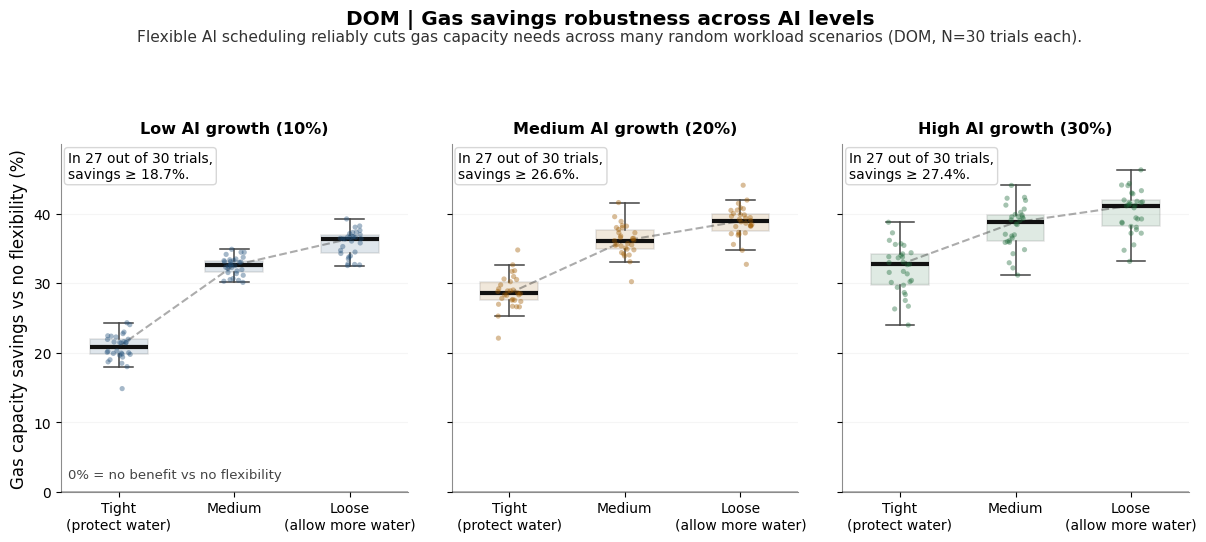

In [16]:
# @title Panel chart: Gas savings distribution across trials (side-by-side AI levels)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _prepare_panel_data(out: pd.DataFrame, region: str, ai_frac: float):
    df = out.copy()
    df["region"] = df["region"].astype(str).str.strip()

    for c in ["ai_fraction", "trial", "gas_improve_pct_vs_noflex"]:
        if c not in df.columns:
            raise ValueError(f"Missing required column: {c}")
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # eps_frac preferred; else derive from eps_idx within each trial
    if "eps_frac" not in df.columns or df["eps_frac"].isna().all():
        if "eps_idx" not in df.columns:
            raise ValueError("Need eps_frac or eps_idx to create Tight/Med/Loose bins.")
        df["eps_idx"] = pd.to_numeric(df["eps_idx"], errors="coerce")
        max_eps = df.groupby(["region", "ai_fraction", "trial"])["eps_idx"].transform("max")
        df["eps_frac"] = df["eps_idx"] / max_eps.replace(0, np.nan)
    else:
        df["eps_frac"] = pd.to_numeric(df["eps_frac"], errors="coerce")

    sub = df[
        (df["region"] == str(region)) &
        np.isclose(df["ai_fraction"], float(ai_frac), atol=1e-9)
    ].dropna(subset=["trial", "eps_frac", "gas_improve_pct_vs_noflex"]).copy()

    if sub.empty:
        raise ValueError(f"No valid rows for region={region}, ai_frac={ai_frac}")

    # Bin by water strictness
    sub["water_bin"] = pd.cut(
        sub["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=["Tight", "Medium", "Loose"]
    )
    sub = sub.dropna(subset=["water_bin"]).copy()
    sub["water_bin"] = sub["water_bin"].astype(str)

    # Per-trial mean within bin (avoids overweighting eps points)
    per_trial = (
        sub.groupby(["trial", "water_bin"], as_index=False)
           .agg(gas_savings_pct=("gas_improve_pct_vs_noflex", "mean"))
    )

    order = ["Tight", "Medium", "Loose"]
    per_trial["water_bin"] = pd.Categorical(per_trial["water_bin"], categories=order, ordered=True)
    per_trial = per_trial.sort_values(["water_bin", "trial"]).reset_index(drop=True)

    # Arrays per bin
    data = []
    for b in order:
        vals = per_trial.loc[per_trial["water_bin"] == b, "gas_savings_pct"].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]
        data.append(vals)

    # Robustness: choose Tight bin p10 => “27/30 trials ≥ p10”
    N = int(per_trial["trial"].nunique())
    tight_vals = data[0]
    p10 = float(np.quantile(tight_vals, 0.10)) if len(tight_vals) else np.nan
    n_ge = int(np.sum(tight_vals >= p10)) if np.isfinite(p10) else 0

    # Medians per bin (for dashed trend line)
    medians = [float(np.median(v)) if len(v) else np.nan for v in data]

    return {
        "data": data,
        "N": N,
        "p10_tight": p10,
        "n_ge_tight": n_ge,
        "medians": medians
    }


def plot_gas_savings_distribution_panel_poster(
    out: pd.DataFrame,
    region: str,
    ai_fracs,
    *,
    show_points: bool = True,
    compact: bool = True,   # True = narrower panels + more spacing
):
    """
    Poster-ready side-by-side panels for multiple AI fractions.

    Implements:
      - Subtitle under main title (main message)
      - Per-panel annotation: "In 27 out of 30 trials, savings ≥ X%"
      - Descriptive water x labels
      - Thicker median lines + dashed median trend line
      - Cleaner points (smaller, more transparent, single color per panel)
      - y-axis starts at 0 + subtle 0% reference label
      - Returns a caption string for poster use
    """

    ai_fracs = [float(a) for a in ai_fracs]

    # Narrative labels above each panel
    def _ai_narrative(a):
        if abs(a - 0.10) < 1e-6: return "Low AI growth (10%)"
        if abs(a - 0.20) < 1e-6: return "Medium AI growth (20%)"
        if abs(a - 0.30) < 1e-6: return "High AI growth (30%)"
        return f"AI level ({int(round(a*100))}%)"

    # Panel colors (one neutral tone per panel)
    panel_colors = ["#1f4e79", "#a15c00", "#1e6b3a", "#6a3d9a"]  # navy, muted orange, green, purple

    # Prepare all panels first
    panels = []
    all_vals = []
    for a in ai_fracs:
        p = _prepare_panel_data(out, region, a)
        panels.append((a, p))
        for v in p["data"]:
            if len(v) > 0:
                all_vals.append(v)

    if not all_vals:
        raise ValueError("No data to plot.")
    all_vals = np.concatenate(all_vals)

    # --- y limits: start at 0, max just above global max ---
    ymax = float(np.max(all_vals))
    y1 = max(5.0, ymax * 1.08)  # small headroom
    y0 = 0.0

    # --- figure layout ---
    n = len(ai_fracs)
    if compact:
        fig_w = 3.7 * n + 1.2
        wspace = 0.28
    else:
        fig_w = 4.2 * n + 1.2
        wspace = 0.18

    fig, axes = plt.subplots(1, n, figsize=(fig_w, 5.6), sharey=True)
    if n == 1:
        axes = [axes]

    # Descriptive water labels (instant meaning)
    xlabels = ["Tight\n(protect water)", "Medium", "Loose\n(allow more water)"]
    x = np.arange(1, 4)

    for idx, (ax, (a, p)) in enumerate(zip(axes, panels)):
        color = panel_colors[idx % len(panel_colors)]
        data = p["data"]
        med = p["medians"]

        # Boxplot: thicker, darker medians
        bp = ax.boxplot(
            data,
            tick_labels=xlabels,
            showfliers=False,
            widths=0.50,
            patch_artist=True,
            medianprops=dict(linewidth=3.0, color="#111111"),
            boxprops=dict(linewidth=1.1, color="#444444"),
            whiskerprops=dict(linewidth=1.1, color="#444444"),
            capprops=dict(linewidth=1.1, color="#444444"),
        )

        # Fill boxes lightly (same fill across bins, keeps focus on trend not colors)
        for patch in bp["boxes"]:
            patch.set_facecolor(color)
            patch.set_alpha(0.14)

        # Points: smaller + more transparent + single color per panel
        if show_points:
            rng = np.random.default_rng(0)
            for i, vals in enumerate(data, start=1):
                if len(vals) == 0:
                    continue
                jitter = rng.uniform(-0.10, 0.10, size=len(vals))
                ax.scatter(
                    np.full(len(vals), i) + jitter,
                    vals,
                    s=14,
                    alpha=0.40,
                    color=color,
                    edgecolors="none",
                    zorder=3
                )

        # Faint dashed line through medians (trend cue)
        if all(np.isfinite(m) for m in med):
            ax.plot(x, med, linestyle="--", linewidth=1.5, alpha=0.35, color="#111111", zorder=2)

        # 0% reference line with subtle label
        ax.axhline(0, color="#666666", lw=1.2, alpha=0.55)
        if idx == 0:
            ax.text(0.02, 0.03, "0% = no benefit vs no flexibility",
                    transform=ax.transAxes, ha="left", va="bottom",
                    fontsize=9.5, color="#444444")

        # Panel header: narrative label + AI level
        ax.set_title(_ai_narrative(a), fontsize=11.5, fontweight="semibold", pad=8)

        # Reliability annotation (reader-friendly)
        N = p["N"]
        p10 = p["p10_tight"]
        n_ge = p["n_ge_tight"]
        if np.isfinite(p10) and N > 0:
            ax.text(
                0.02, 0.98,
                f"In {n_ge} out of {N} trials,\nsavings ≥ {p10:.1f}%.",
                transform=ax.transAxes,
                ha="left", va="top",
                fontsize=10.0,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#d0d0d0", alpha=0.85)
            )

        # Axis styling
        ax.set_ylim(y0, y1)
        ax.grid(True, axis="y", alpha=0.12, linewidth=0.8)
        ax.grid(False, axis="x")
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_alpha(0.45)
        ax.spines["bottom"].set_alpha(0.45)

    # Shared y label
    axes[0].set_ylabel("Gas capacity savings vs no flexibility (%)", fontsize=12)

    # Main title + subtitle (main message)
    fig.suptitle(
        f"{region.upper()} | Gas savings robustness across AI levels",
        fontsize=14.5, fontweight="semibold", y=0.99
    )
    fig.text(
        0.5, 0.94,
        f"Flexible AI scheduling reliably cuts gas capacity needs across many random workload scenarios "
        f"({region.upper()}, N=30 trials each).",
        ha="center", va="center", fontsize=11.2, color="#333333"
    )

    # Spacing between panels
    plt.subplots_adjust(top=0.86, wspace=wspace)
    plt.tight_layout(rect=[0, 0.03, 1, 0.88])

    # Poster caption you can paste under the figure
    caption = (
        "Each box shows how much peak gas capacity is reduced when AI jobs are scheduled flexibly instead of immediately, "
        "across 30 random workload scenarios. Moving from Tight→Loose water caps increases typical savings, and higher AI "
        "adoption (right panels) generally yields larger benefits."
    )
    print("\nPOSTER CAPTION:\n" + caption)

    return fig, axes, caption


# --- Usage ---
# Recommendation for posters: 2 panels is usually perfect (less clutter)
# fig, axes, caption = plot_gas_savings_distribution_panel_poster(out, region="PJME", ai_fracs=[0.10, 0.30], compact=True)

# If you want all 3:
fig, axes, caption = plot_gas_savings_distribution_panel_poster(out, region="DOM", ai_fracs=[0.10, 0.20, 0.30], compact=True)
plt.show()



POSTER CAPTION:
Same total AI energy delivered, but flexible scheduling cuts peak gas needs 10% by shifting jobs from the peak hour (~hour 14) to shoulder periods while avoiding high-water hours (green).


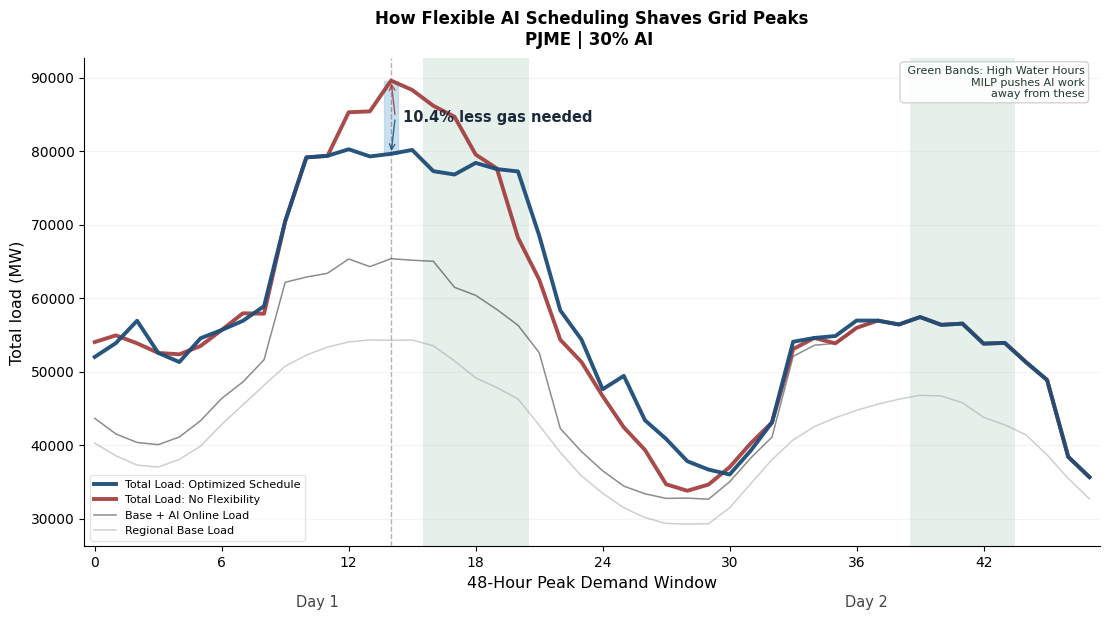

In [52]:
# @title Flexibility Chart: Flexible AI Job Scheduling to achieve efficiency

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_48h_load_profile_from_saved_files(
    BASE_DIR: str,
    out: pd.DataFrame,
    *,
    region: str = "DOM",
    ai_frac: float = 0.10,        # total AI level stored in out["ai_fraction"]
    trial: int = 0,
    eps_pick: str = "mid",        # "tight" (low eps_idx), "mid", "loose" (high eps_idx)
    eps_idx: int | None = None,   # override eps_pick if provided
    water_top_frac: float = 0.20, # shade top 20% water-intensity hours
    plot_seed: int = 123
):
    WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

    if not os.path.exists(WINDOWS_PATH) or not os.path.exists(WORKLOADS_PATH):
        raise FileNotFoundError(
            "Missing inputs for 48h profile. You need BOTH:\n"
            f"  - {WINDOWS_PATH}\n"
            f"  - {WORKLOADS_PATH}\n"
            "These are created by your Phase 1/2 precalc cells (run_window_precalc + run_workload_precalc)."
        )

    windows_df = pd.read_csv(WINDOWS_PATH)
    workloads_df = pd.read_csv(WORKLOADS_PATH)

    # --- window for region ---
    wdf = windows_df.copy()
    wdf["region"] = wdf["region"].astype(str).str.strip()
    wdf = wdf[wdf["region"] == str(region)].copy()
    if wdf.empty:
        raise ValueError(f"No window found for region={region} in {WINDOWS_PATH}")

    wdf["hour_idx"] = pd.to_numeric(wdf["hour_idx"], errors="coerce")
    wdf = wdf.sort_values("hour_idx")
    L_base = pd.to_numeric(wdf["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(wdf["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all():
        raise ValueError("Non-finite values in L_base or w_vec (check cleaned_regional_windows.csv).")

    T = int(len(L_base))
    L_max = float(np.max(L_base))

    # --- jobs for scenario ---
    jdf = workloads_df.copy()
    jdf["region"] = jdf["region"].astype(str).str.strip()
    jdf["ai_fraction"] = pd.to_numeric(jdf["ai_fraction"], errors="coerce")
    jdf["trial"] = pd.to_numeric(jdf["trial"], errors="coerce")

    jobs_rows = jdf[
        (jdf["region"] == str(region)) &
        (np.isclose(jdf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (jdf["trial"].astype(int) == int(trial))
    ].copy()
    if jobs_rows.empty:
        raise ValueError(f"No jobs found for region={region}, ai_frac={ai_frac}, trial={trial} in {WORKLOADS_PATH}")

    jobs = jobs_rows[["id","p","d","r","e"]].to_dict("records")




    # # --- reconstruct SAME seed logic used in your precalc ---
    # unique_regions = list(jdf["region"].dropna().astype(str).unique())
    # unique_ai = sorted(list(jdf["ai_fraction"].dropna().astype(float).unique()))

    # try:
    #     region_to_i = {str(r): i for i, r in enumerate(REGIONS)}  # noqa: F821
    # except Exception:
    #     region_to_i = {r: i for i, r in enumerate(unique_regions)}

    # try:
    #     ai_levels = [float(a) for a in AI_LOAD_LEVELS]            # noqa: F821
    #     ai_to_i = {a: i for i, a in enumerate(ai_levels)}
    # except Exception:
    #     ai_to_i = {a: i for i, a in enumerate(unique_ai)}

    # if float(ai_frac) not in ai_to_i:
    #     closest = min(ai_to_i.keys(), key=lambda x: abs(x - float(ai_frac)))
    #     if abs(closest - float(ai_frac)) > 1e-6:
    #         raise ValueError(f"ai_frac={ai_frac} not found in AI levels; nearest is {closest}")
    #     ai_key = closest
    # else:
    #     ai_key = float(ai_frac)

    # if str(region) not in region_to_i:
    #     raise ValueError(f"region={region} not found in region index mapping.")






    # seed = int(int(trial) + 10_000*region_to_i[str(region)] + 1_000_000*ai_to_i[ai_key])
    # rng = np.random.default_rng(seed)

    # FIXED plotting seed (stable chart across notebooks/runs)
    rng = np.random.default_rng(int(plot_seed))

    # Online AI portion (your calibration)
    ai_online_portion = 0.5 * float(ai_frac)
    L_online = build_online_ai_load(wdf, L_max, ai_online_portion, rng)  # must exist

    L_online = np.asarray(L_online, dtype=float)
    if len(L_online) != T or not np.isfinite(L_online).all():
        raise ValueError("Bad L_online generated.")

    # --- pick ε point from out (for this region/ai/trial) ---
    odf = out.copy()
    odf["region"] = odf["region"].astype(str).str.strip()
    odf["ai_fraction"] = pd.to_numeric(odf["ai_fraction"], errors="coerce")
    odf["trial"] = pd.to_numeric(odf["trial"], errors="coerce")
    odf["eps_idx"] = pd.to_numeric(odf["eps_idx"], errors="coerce")
    odf["epsilon_water_cap"] = pd.to_numeric(odf["epsilon_water_cap"], errors="coerce")

    sub = odf[
        (odf["region"] == str(region)) &
        (np.isclose(odf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (odf["trial"].astype(int) == int(trial))
    ].dropna(subset=["eps_idx","epsilon_water_cap"]).copy()

    if sub.empty:
        raise ValueError("No ε results found in `out` for this region/ai/trial.")

    sub = sub.sort_values("eps_idx")
    if eps_idx is None:
        if eps_pick == "tight":
            eps_idx = int(sub["eps_idx"].iloc[0])
        elif eps_pick == "loose":
            eps_idx = int(sub["eps_idx"].iloc[-1])
        else:
            eps_idx = int(sub["eps_idx"].iloc[len(sub)//2])

    row = sub[sub["eps_idx"].astype(int) == int(eps_idx)]
    if row.empty:
        raise ValueError(f"eps_idx={eps_idx} not available for this trial. Have: {sorted(sub['eps_idx'].unique())}")

    water_epsilon = float(row["epsilon_water_cap"].iloc[0])

    # --- schedules ---
    def_no = schedule_no_flex(jobs, T)  # must exist
    L_no = L_base + L_online + def_no

    sol = solve_milp_with_schedule(
        L_base=L_base,
        L_online=L_online,
        jobs=jobs,
        w_vec=w_vec,
        alpha=STRESS_ALPHA,
        rho=RHO,
        import_limit_MW=IMPORT_LIMIT_MW,
        mode="epsilon",
        water_epsilon=water_epsilon
    )

    if not sol.get("has_solution", False):
        raise RuntimeError(f"MILP produced no readable solution (status={sol.get('status')}).")

    def_opt = np.asarray(sol.get("deferr_mw", np.full(T, np.nan)), dtype=float)
    if not np.isfinite(def_opt).all():
        raise RuntimeError(f"MILP returned non-finite schedule (status={sol.get('status')}).")

    L_opt = L_base + L_online + def_opt

    # --- peak metrics ---
    peak_t = int(np.argmax(L_no))
    peak_no = float(np.max(L_no))
    peak_opt = float(np.max(L_opt))
    peak_reduction_pct = 100.0 * (peak_no - peak_opt) / max(peak_no, 1e-9)

    # For annotation: point between red and blue at peak hour
    y_mid = 0.5 * (L_no[peak_t] + L_opt[peak_t])

    # --- water shading (top X%) ---
    thr = float(np.quantile(w_vec, 1.0 - float(water_top_frac)))
    high_water = (w_vec >= thr)

    # --- plot ---
    x = np.arange(T)

    # Muted, poster-friendly palette
    COL_BASE  = "#9aa0a6"  # soft gray
    COL_NO    = "#a23b3b"  # muted red
    COL_OPT   = "#1f4e79"  # muted navy
    COL_WATER = "#2e8b57"  # muted green
    COL_GAP   = "#9ecae1"  # light blue fill

    fig, ax = plt.subplots(figsize=(11.2, 6.3))

    # Water shading (slightly stronger + clear meaning via box)
    for t in range(T):
        if high_water[t]:
            ax.axvspan(t - 0.5, t + 0.5, color=COL_WATER, alpha=0.12, linewidth=0, zorder=0)

    # # Core lines (legend labels updated)
    # ax.plot(x, L_base, color=COL_BASE, linewidth=2.0, alpha=0.55, label="Regional Base Load", zorder=2)
    # ax.plot(x, L_no,   color=COL_NO,   linewidth=2.8, alpha=0.92, label="Total Load: No Flexibility", zorder=3)
    # ax.plot(x, L_opt,  color=COL_OPT,  linewidth=3.4, alpha=0.96, label="Total Load: Optimized Schedule", zorder=4)

    # # NEW: show AI online component (thin black line, subtle)
    # ax.plot(
    #     x, (L_base + L_online),
    #     color="black", linewidth=1.2, alpha=0.55, linestyle="-",
    #     label="Base + AI Online Load", zorder=2.5
    # )

    # Main story first (controls legend order too)
    ax.plot(x, L_opt,  color=COL_OPT,  linewidth=2.8, alpha=0.96, label="Total Load: Optimized Schedule", zorder=4)
    ax.plot(x, L_no,   color=COL_NO,   linewidth=2.8, alpha=0.92, label="Total Load: No Flexibility", zorder=3)

    # Supporting lines
    ax.plot(x, (L_base + L_online), color="black", linewidth=1.1, alpha=0.45,
            label="Base + AI Online Load", zorder=2.5)
    ax.plot(x, L_base, color=COL_BASE, linewidth=1.1, alpha=0.50,
            label="Regional Base Load", zorder=2)


    # Peak gap highlight at peak hour: vertical span from red down to blue
    ax.fill_between(
        [peak_t - 0.35, peak_t + 0.35],
        [L_opt[peak_t], L_opt[peak_t]],
        [L_no[peak_t],  L_no[peak_t]],
        color=COL_GAP, alpha=0.55, zorder=1
    )
    ax.text(
        peak_t + 0.55, y_mid,
        f"{peak_reduction_pct:.1f}% less gas needed",
        fontsize=10.5, fontweight="semibold", color="#1b2a3a",
        va="center"
    )

    # Peak marker (subtle)
    ax.axvline(peak_t, color="black", linestyle="--", linewidth=1.0, alpha=0.30, zorder=1)

    # Peak annotation: point to BOTH red and blue at peak hour
    # ax.annotate(
    #     f"Peak reduced {peak_reduction_pct:.1f}%\n(same AI energy)",
    #     xy=(peak_t, y_mid),
    #     xytext=(min(T - 1, peak_t + 4), y_mid + 0.05*(peak_no - np.min(L_base) + 1)),
    #     arrowprops=dict(arrowstyle="->", color=COL_OPT, lw=1.2, alpha=0.95),
    #     # fontsize=11.0, fontweight="semibold", color=COL_OPT,
    #     fontsize=9.0, color=COL_OPT,
    #     bbox=dict(boxstyle="round,pad=0.28", facecolor="white", edgecolor="#d0d0d0", alpha=0.90),
    #     zorder=5
    # )
    # y_top = ax.get_ylim()[1]
    # y_text = y_top - 0.08 * (y_top - ax.get_ylim()[0])

    # ax.annotate(
    #     f"Peak reduced {peak_reduction_pct:.1f}%\n(same AI energy)",
    #     xy=(peak_t, y_mid),
    #     xytext=(min(T - 1, peak_t + 10), y_text),
    #     arrowprops=dict(arrowstyle="->", color=COL_OPT, lw=1.2, alpha=0.95),
    #     # fontsize=11.0, fontweight="semibold", color=COL_OPT,
    #     fontsize=9.0, color=COL_OPT,
    #     bbox=dict(boxstyle="round,pad=0.28", facecolor="white",
    #               edgecolor="#d0d0d0", alpha=0.90),
    #     zorder=5
    # )

    # second arrow to red peak (manual small arrow)
    ax.annotate(
        "",
        xy=(peak_t, L_no[peak_t]),
        xytext=(peak_t + 0.2, y_mid),
        arrowprops=dict(arrowstyle="->", color=COL_NO, lw=1.0, alpha=0.85),
        zorder=5
    )
    # third arrow to blue peak at same hour
    ax.annotate(
        "",
        xy=(peak_t, L_opt[peak_t]),
        xytext=(peak_t + 0.2, y_mid),
        arrowprops=dict(arrowstyle="->", color=COL_OPT, lw=1.0, alpha=0.85),
        zorder=5
    )

    # Stronger, explicit water explanation box (upper right)
    ax.text(
        0.985, 0.985,
        " Green Bands: High Water Hours\nMILP pushes AI work\naway from these",
        transform=ax.transAxes,
        ha="right", va="top",
        # fontsize=9.0, fontweight="semibold", color="#1f3a2b",
        fontsize=8.0, color="#1f3a2b",
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#d0d0d0", alpha=0.92)
    )

    # X-axis: clearer label + Day 1 / Day 2
    ax.set_xlim(-0.5, T - 0.5)
    ax.set_xlabel("48-Hour Peak Demand Window", fontsize=11.5)
    ax.set_ylabel("Total load (MW)", fontsize=11.5)

    ax.set_xticks(np.arange(0, T, 6))
    ax.text(0.23, -0.10, "Day 1", transform=ax.transAxes, ha="center", va="top", fontsize=10.5, color="#444444")
    ax.text(0.77, -0.10, "Day 2", transform=ax.transAxes, ha="center", va="top", fontsize=10.5, color="#444444")

    # Grid: y-only, very light
    ax.grid(True, axis="y", alpha=0.14, linewidth=0.8)
    ax.grid(False, axis="x")

    # Clean spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Title: rewritten (per feedback)
    ax.set_title(
        "How Flexible AI Scheduling Shaves Grid Peaks\n"
        # f"{region.upper()} | {int(ai_frac*100)}% AI | trial={trial} | ε_idx={eps_idx} (ε={water_epsilon:.0f})",
        f"{region.upper()} | {int(ai_frac*100)}% AI ",
        fontsize=12.0, fontweight="semibold", pad=10
    )

    # Legend: updated text, quiet box
    leg = ax.legend(loc="lower left", frameon=True, framealpha=0.58, fontsize=8)
    leg.get_frame().set_edgecolor("#d0d0d0")
    leg.get_frame().set_linewidth(0.9)

    plt.tight_layout()

    # Perfect one-sentence poster caption (per feedback)
    caption = (
        f"Same total AI energy delivered, but flexible scheduling cuts peak gas needs "
        f"{peak_reduction_pct:.0f}% by shifting jobs from the peak hour (~hour {peak_t}) to shoulder periods "
        f"while avoiding high-water hours (green)."
    )
    print("\nPOSTER CAPTION:\n" + caption)

    return fig, ax


# --- Usage ---
fig, ax = plot_48h_load_profile_from_saved_files(
    BASE_DIR=BASE_DIR,
    out=out,
    region="PJME",
    ai_frac=0.30,
    trial=0,
    eps_pick="mid",
    water_top_frac=0.20
)
plt.show()


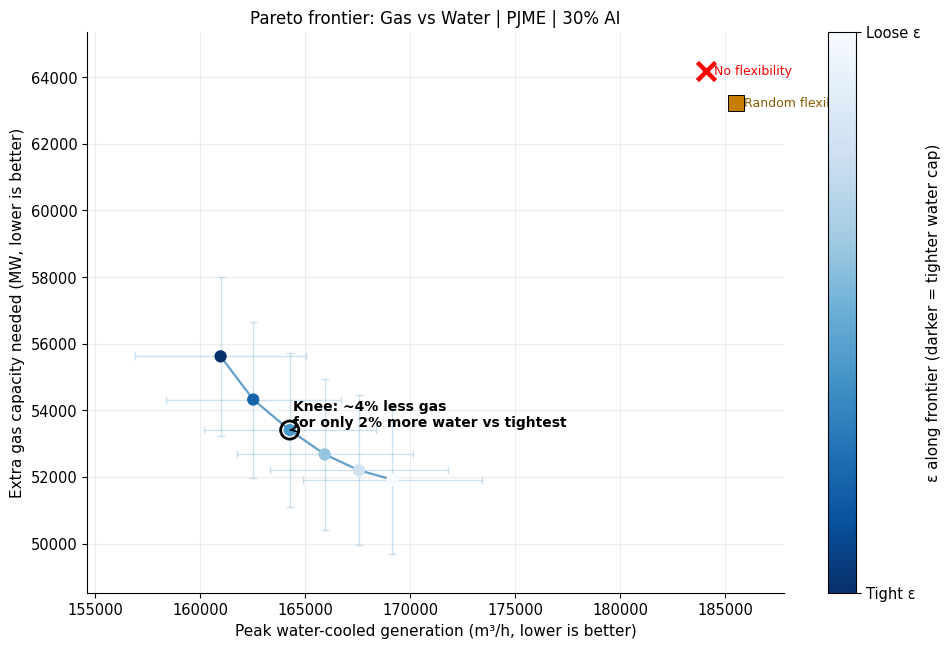

In [60]:
# @title Pareto Chart: Pareto Frontier Chart; Gas vs. Water

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _knee_index(w, g):
    """Knee = point with max perpendicular distance to line from first->last (normalized)."""
    w = np.asarray(w, dtype=float)
    g = np.asarray(g, dtype=float)
    if len(w) < 3:
        return None

    # normalize to [0,1]
    wn = (w - w.min()) / max(w.max() - w.min(), 1e-12)
    gn = (g - g.min()) / max(g.max() - g.min(), 1e-12)

    p1 = np.array([wn[0], gn[0]])
    p2 = np.array([wn[-1], gn[-1]])
    v = p2 - p1
    denom = np.linalg.norm(v)
    if denom < 1e-12:
        return None

    d = np.zeros(len(w))
    for i in range(len(w)):
        p = np.array([wn[i], gn[i]])
        # 2D "cross product magnitude" trick
        d[i] = abs(v[0]*(p[1]-p1[1]) - v[1]*(p[0]-p1[0])) / denom

    d[0] = -1
    d[-1] = -1
    return int(np.argmax(d))


def plot_pareto_frontier_with_baselines(
    out: pd.DataFrame,
    *,
    region: str,
    ai_frac: float,
    sort_by: str = "eps_idx",          # "eps_idx" or "epsilon_water_cap"
    show_errorbars: bool = True,
    ai_atol: float = 1e-8,             # float match tolerance
    allow_closest_ai: bool = True,     # if exact ai_frac not present, pick closest available
    region_casefold: bool = True,      # normalize region strings for matching
):
    """
    Pareto frontier (MILP ε points averaged across trials) + baselines.

    Robust behaviors:
      - region normalization (strip + optional upper)
      - ai_fraction numeric coercion + isclose matching; optional nearest fallback
      - std NaNs -> 0 (for single trial)
      - handles missing baseline cols by skipping those markers
      - knee annotation only if >=3 frontier points
    """

    if out is None or len(out) == 0:
        raise ValueError("`out` is empty.")

    df = out.copy()

    # ---- required cols for frontier ----
    required = {"region", "ai_fraction", "trial", "eps_idx", "epsilon_water_cap", "gas_peak_mw", "water_peak_m3h"}
    missing = sorted(list(required - set(df.columns)))
    if missing:
        raise ValueError(f"`out` is missing required columns for Pareto frontier: {missing}")

    # ---- normalize region ----
    if region_casefold:
        df["region_norm"] = df["region"].astype(str).str.strip().str.upper()
        region_key = str(region).strip().upper()
    else:
        df["region_norm"] = df["region"].astype(str).str.strip()
        region_key = str(region).strip()

    # ---- numeric coercions ----
    for c in ["ai_fraction", "trial", "eps_idx", "epsilon_water_cap", "gas_peak_mw", "water_peak_m3h"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # Filter to region first
    df = df[df["region_norm"] == region_key].copy()
    if df.empty:
        avail = sorted(df["region_norm"].dropna().unique().tolist()) if "region_norm" in df else []
        raise ValueError(f"No rows found for region={region_key}. (Check region name; normalization is on.)")

    # ---- AI fraction match ----
    ai_frac = float(ai_frac)
    df_ai = df[np.isclose(df["ai_fraction"], ai_frac, atol=ai_atol)].copy()

    if df_ai.empty:
        avail_ai = sorted(df["ai_fraction"].dropna().unique().tolist())
        if not avail_ai:
            raise ValueError(f"No valid ai_fraction values in data for region={region_key}.")

        if not allow_closest_ai:
            raise ValueError(
                f"No rows found for region={region_key} and ai_frac={ai_frac}. "
                f"Available ai_fraction values: {avail_ai}"
            )

        closest = min(avail_ai, key=lambda x: abs(float(x) - ai_frac))
        df_ai = df[np.isclose(df["ai_fraction"], float(closest), atol=ai_atol)].copy()
        if df_ai.empty:
            raise ValueError(
                f"Could not match requested ai_frac={ai_frac} or closest={closest} for region={region_key}."
            )
        print(f"[INFO] ai_frac={ai_frac} not found exactly. Using closest available ai_frac={closest}.")
        ai_frac = float(closest)

    # Drop rows without core MILP values
    df_ai = df_ai.dropna(subset=["eps_idx", "epsilon_water_cap", "gas_peak_mw", "water_peak_m3h", "trial"]).copy()
    if df_ai.empty:
        raise ValueError("After numeric cleanup, no valid MILP rows remain for this region/ai_frac.")

    # ---- frontier stats across trials per eps point ----
    frontier = (
        df_ai.groupby("eps_idx", as_index=False)
            .agg(
                epsilon_mean=("epsilon_water_cap", "mean"),
                water_mean=("water_peak_m3h", "mean"),
                water_std =("water_peak_m3h", "std"),
                gas_mean  =("gas_peak_mw", "mean"),
                gas_std   =("gas_peak_mw", "std"),
                n_trials  =("trial", "nunique"),
            )
    )

    # sort frontier
    if sort_by == "epsilon_water_cap":
        frontier = frontier.sort_values("epsilon_mean")
    else:
        frontier = frontier.sort_values("eps_idx")

    frontier = frontier.reset_index(drop=True)

    # std can be NaN when n_trials=1; make it 0 for clean errorbars
    frontier["water_std"] = frontier["water_std"].fillna(0.0)
    frontier["gas_std"] = frontier["gas_std"].fillna(0.0)

    # ---- baselines (optional) ----
    baseline_cols = ["gas_no_flex_mw","water_no_flex_m3h","gas_random_mw","water_random_m3h"]
    have_all_baselines = all(c in df_ai.columns for c in baseline_cols)

    noflex_gas = noflex_water = rand_gas = rand_water = None
    if have_all_baselines:
        for c in baseline_cols:
            df_ai[c] = pd.to_numeric(df_ai[c], errors="coerce")

        per_trial = (
            df_ai.sort_values("eps_idx")
                .groupby("trial", as_index=False)
                .first()
                .dropna(subset=baseline_cols)
        )

        if len(per_trial) > 0:
            noflex_gas   = float(per_trial["gas_no_flex_mw"].mean())
            noflex_water = float(per_trial["water_no_flex_m3h"].mean())
            rand_gas     = float(per_trial["gas_random_mw"].mean())
            rand_water   = float(per_trial["water_random_m3h"].mean())

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(9.8, 6.6))

    # Color gradient along frontier: darker = tighter water cap (first point)
    cvals = np.linspace(0, 1, len(frontier)) if len(frontier) > 1 else np.array([0.0])
    sc = ax.scatter(
        frontier["water_mean"], frontier["gas_mean"],
        c=cvals, cmap="Blues_r", s=78, edgecolors="none",
        label="MILP ε-frontier", zorder=3
    )
    ax.plot(frontier["water_mean"], frontier["gas_mean"], linewidth=1.6, alpha=0.7, zorder=2)

    # Error bars
    if show_errorbars and len(frontier) > 0:
        ax.errorbar(
            frontier["water_mean"], frontier["gas_mean"],
            xerr=frontier["water_std"], yerr=frontier["gas_std"],
            fmt="none", ecolor="tab:blue", alpha=0.22, capsize=3, linewidth=1, zorder=1
        )

    # Baselines (only if available)
    if noflex_gas is not None and noflex_water is not None:
        ax.scatter([noflex_water], [noflex_gas], marker="x", s=170, linewidths=3.2, color="red", zorder=5)
        ax.text(noflex_water, noflex_gas, "  No flexibility", va="center", ha="left", fontsize=9, color="red")

    if rand_gas is not None and rand_water is not None:
        ax.scatter([rand_water], [rand_gas], marker="s", s=120, color="#c77c02",
                   edgecolor="black", linewidth=0.7, zorder=5)
        ax.text(rand_water, rand_gas, "  Random flexibility", va="center", ha="left", fontsize=9, color="#8a5a00")

    # Axis labels (your wording)
    ax.set_xlabel("Peak water-cooled generation (m³/h, lower is better)")
    ax.set_ylabel("Extra gas capacity needed (MW, lower is better)")
    ax.set_title(f"Pareto frontier: Gas vs Water | {region_key} | {int(round(ai_frac*100))}% AI")

    ax.grid(True, alpha=0.22)
    ax.margins(x=0.08, y=0.08)

    # Colorbar direction cue
    cbar = plt.colorbar(sc, ax=ax)
    cbar.set_label("ε along frontier (darker = tighter water cap)")
    cbar.set_ticks([0, 1] if len(frontier) > 1 else [0])
    cbar.set_ticklabels(["Tight ε", "Loose ε"] if len(frontier) > 1 else ["ε"])

    # Knee annotation
    k = _knee_index(frontier["water_mean"].values, frontier["gas_mean"].values)
    if k is not None:
        w0 = float(frontier["water_mean"].iloc[0])
        g0 = float(frontier["gas_mean"].iloc[0])
        wk = float(frontier["water_mean"].iloc[k])
        gk = float(frontier["gas_mean"].iloc[k])

        gas_less_pct = 100.0 * (g0 - gk) / max(g0, 1e-12)
        water_more_pct = 100.0 * (wk - w0) / max(w0, 1e-12)

        ax.scatter([wk], [gk], s=170, facecolors="none", edgecolors="black", linewidths=2, zorder=6)
        ax.annotate(
            f"Knee: ~{gas_less_pct:.0f}% less gas\nfor only {water_more_pct:.0f}% more water vs tightest",
            xy=(wk, gk),
            xytext=(wk + 0.02*(frontier["water_mean"].max() - frontier["water_mean"].min() + 1e-9),
                    gk + 0.03*(frontier["gas_mean"].max() - frontier["gas_mean"].min() + 1e-9)),
            arrowprops=dict(arrowstyle="->", linewidth=1.2),
            fontsize=10,
            fontweight="bold",
            zorder=7
        )

    plt.tight_layout()
    return fig, ax, frontier


# Example usage:
fig, ax, frontier = plot_pareto_frontier_with_baselines(out, region="PJME", ai_frac=0.30)
plt.show()


/tmp/ipython-input-2686615137.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sub.groupby(["trial", "water_bin"], as_index=False)
/tmp/ipython-input-2686615137.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_trial.groupby("water_bin", as_index=False)
/tmp/ipython-input-2686615137.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sub.groupby(["trial", "water_bin"], as_index=False)
/tmp/ipython-input-26866

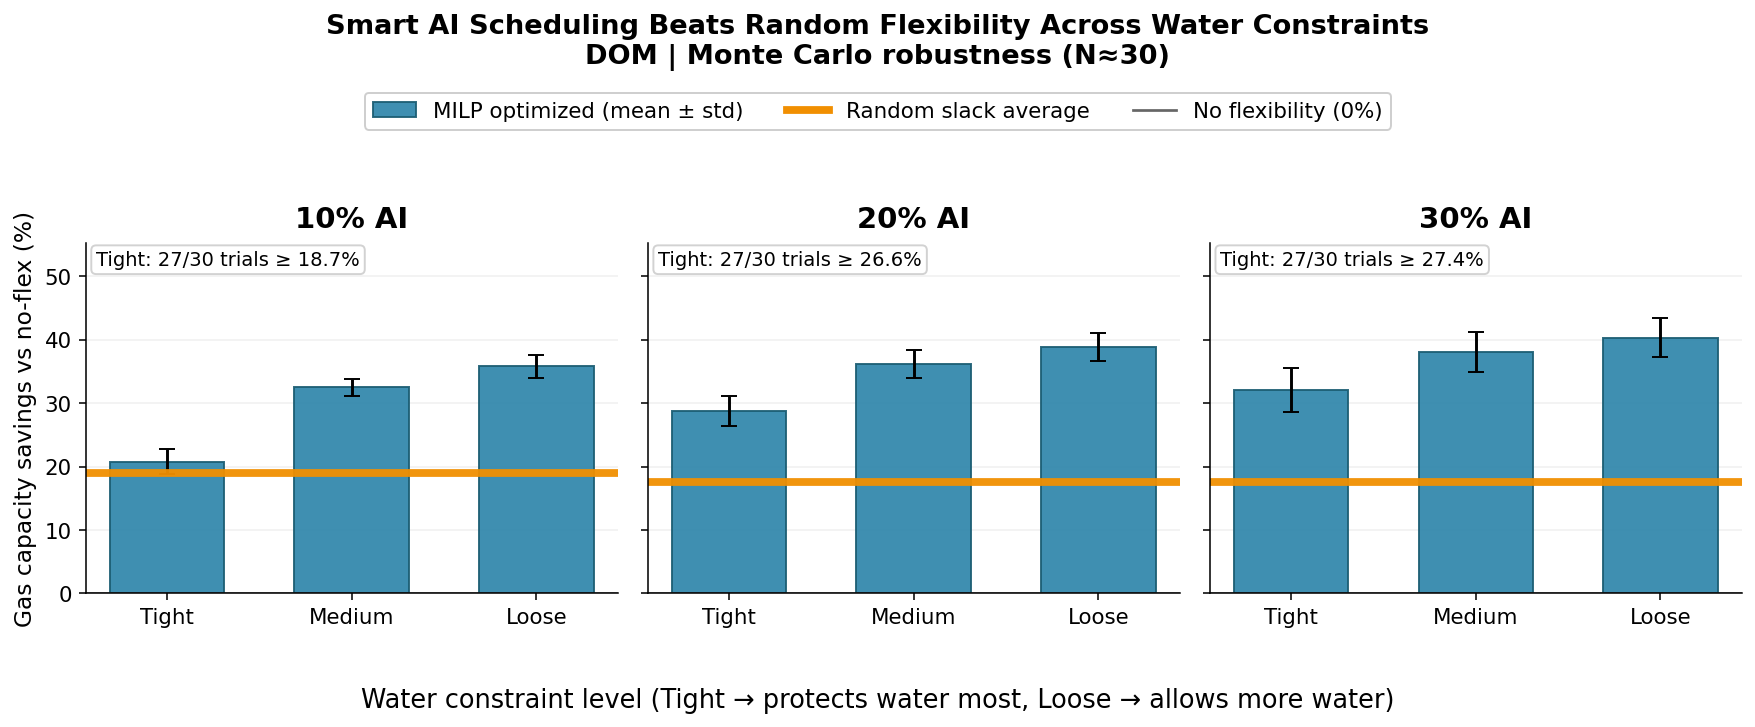

In [64]:
# @title Smart Scheduling vs Baselines

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Sequence, Tuple

def plot_flexibility_benefits_panels(
    df: pd.DataFrame,
    region: str = "PJME",
    ai_fracs: Sequence[float] = (0.10, 0.20, 0.30),
    bins: Tuple[str, str, str] = ("Tight", "Medium", "Loose"),
    robust_bin: str = "Tight",
    robust_quantile: float = 10.0,   # 10th percentile => "90% of trials ≥ X"
):
    """
    3-panel poster chart for a region:
      - Each panel = one AI adoption level
      - Bars = MILP mean ± std gas savings vs no-flex (%)
      - Orange thick line = random slack average
      - 0% line = no-flex reference
      - Judge stat per panel: "Tight: 27/30 trials ≥ X%"
    """

    # ---------- validate ----------
    work = df.copy()
    if "region" not in work.columns:
        raise ValueError("df must include 'region'.")

    work["region"] = work["region"].astype(str).str.strip()

    need = ["ai_fraction", "trial", "eps_idx", "gas_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]
    missing = [c for c in need if c not in work.columns]
    if missing:
        raise ValueError(f"df missing columns: {missing}")

    for c in need:
        work[c] = pd.to_numeric(work[c], errors="coerce")

    # We'll build per-panel stats first so we can share y-limits
    panel_data = []

    for ai_frac in ai_fracs:
        sub = work[
            (work["region"] == str(region)) &
            np.isclose(work["ai_fraction"], float(ai_frac), atol=1e-8)
        ].dropna(subset=["trial", "eps_idx", "gas_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]).copy()

        if sub.empty:
            panel_data.append((ai_frac, None, None, None))
            continue

        # derive eps_frac if needed
        if "eps_frac" in sub.columns:
            sub["eps_frac"] = pd.to_numeric(sub["eps_frac"], errors="coerce")
        else:
            max_eps = sub.groupby("trial")["eps_idx"].transform("max").replace(0, np.nan)
            sub["eps_frac"] = sub["eps_idx"] / max_eps

        sub = sub.dropna(subset=["eps_frac"]).copy()

        # 3 bins
        sub["water_bin"] = pd.cut(
            sub["eps_frac"],
            bins=[-np.inf, 1/3, 2/3, np.inf],
            labels=list(bins)
        )
        sub = sub.dropna(subset=["water_bin"]).copy()

        # per-trial mean within bin (prevents overweighting eps points)
        per_trial = (
            sub.groupby(["trial", "water_bin"], as_index=False)
               .agg(gas_sav=("gas_improve_pct_vs_noflex", "mean"))
        )

        # across trials stats per bin
        stats = (
            per_trial.groupby("water_bin", as_index=False)
                     .agg(
                         gas_mean=("gas_sav", "mean"),
                         gas_std=("gas_sav", "std"),
                         n_trials=("trial", "nunique")
                     )
        )
        stats["water_bin"] = pd.Categorical(stats["water_bin"], categories=list(bins), ordered=True)
        stats = stats.sort_values("water_bin").reset_index(drop=True)
        stats["gas_std"] = stats["gas_std"].fillna(0.0)

        # random slack baseline (one per trial)
        trial_base = sub.groupby("trial")[["gas_no_flex_mw", "gas_random_mw"]].first().dropna()
        random_pct = 100.0 * (trial_base["gas_no_flex_mw"] - trial_base["gas_random_mw"]) / trial_base["gas_no_flex_mw"]
        r_mean = float(random_pct.mean())

        # robustness stat for chosen bin (default Tight)
        rb = per_trial[per_trial["water_bin"].astype(str) == str(robust_bin)]["gas_sav"].dropna().to_numpy()
        if len(rb) > 0:
            thr = float(np.percentile(rb, robust_quantile))  # e.g. 10th percentile
            count = int(np.sum(rb >= thr))
            n = int(len(rb))
            robust_txt = f"{robust_bin}: {count}/{n} trials ≥ {thr:.1f}%"
        else:
            robust_txt = f"{robust_bin}: not enough data"

        panel_data.append((ai_frac, stats, r_mean, robust_txt))

    # ---------- global y-limit for consistent comparison ----------
    ymax = 0.0
    for ai_frac, stats, r_mean, _txt in panel_data:
        if stats is None:
            continue
        local = float(np.nanmax(stats["gas_mean"] + stats["gas_std"]))
        ymax = max(ymax, local, float(r_mean))
    ymax = max(5.0, ymax * 1.25 + 1.0)

    # ---------- styling ----------
    plt.rcParams.update({
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    fig, axes = plt.subplots(
        1, len(ai_fracs),
        figsize=(13.2, 4.9),
        dpi=140,
        sharey=True
    )
    if len(ai_fracs) == 1:
        axes = [axes]

    bar_color = "#2E86AB"
    bar_edge  = "#1C5D73"
    rand_color = "#F18F01"

    for ax, (ai_frac, stats, r_mean, robust_txt) in zip(axes, panel_data):
        ax.set_axisbelow(True)
        ax.grid(True, axis="y", alpha=0.16, linewidth=0.9)
        ax.grid(False, axis="x")

        # If missing data for this AI frac
        if stats is None:
            ax.set_title(f"{int(round(ai_frac*100))}% AI\n(no data)", fontweight="semibold")
            ax.set_xticks([0,1,2])
            ax.set_xticklabels(list(bins))
            ax.set_ylim(0, ymax)
            ax.axhline(0, color="#666666", lw=1.4, alpha=0.7)
            continue

        x = np.arange(len(stats))

        # Bars (MILP)
        ax.bar(
            x, stats["gas_mean"],
            yerr=stats["gas_std"],
            width=0.62,
            color=bar_color,
            edgecolor=bar_edge,
            linewidth=1.0,
            alpha=0.92,
            capsize=4,
        )

        # Random slack baseline
        ax.axhline(r_mean, color=rand_color, lw=4.0, alpha=0.95)

        # 0% line
        ax.axhline(0, color="#666666", lw=1.4, alpha=0.7)

        ax.set_xticks(x)
        ax.set_xticklabels([str(b) for b in stats["water_bin"]])
        ax.set_ylim(0, ymax)

        ax.set_title(f"{int(round(ai_frac*100))}% AI", fontweight="semibold", pad=8)

        # Judge-friendly robustness box (top-left, consistent position)
        ax.text(
            0.02, 0.98,
            robust_txt,
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=10,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#d0d0d0", alpha=0.95)
        )

    # shared labels + title
    axes[0].set_ylabel("Gas capacity savings vs no-flex (%)")
    fig.suptitle(
        f"Smart AI Scheduling Beats Random Flexibility Across Water Constraints\n{str(region).upper()} | Monte Carlo robustness (N≈{int(pd.to_numeric(df.get('trial', pd.Series())).nunique()) if 'trial' in df.columns else '—'})",
        fontsize=14, fontweight="semibold", y=1.03
    )
    fig.supxlabel("Water constraint level (Tight → protects water most, Loose → allows more water)")

    # clean legend (single, for whole figure)
    # Use invisible handles for a neat global legend
    from matplotlib.lines import Line2D
    legend_handles = [
        plt.Rectangle((0,0),1,1, facecolor=bar_color, edgecolor=bar_edge, alpha=0.92, label="MILP optimized (mean ± std)"),
        Line2D([0],[0], color=rand_color, lw=4.0, label="Random slack average"),
        Line2D([0],[0], color="#666666", lw=1.4, label="No flexibility (0%)"),
    ]
    fig.legend(handles=legend_handles, loc="upper center", ncol=3, frameon=True, framealpha=0.95, bbox_to_anchor=(0.5, 0.93))

    plt.tight_layout(rect=[0.02, 0.03, 0.98, 0.90])
    return fig, axes


# Example:
fig, axes = plot_flexibility_benefits_panels(out, region="DOM", ai_fracs=(0.10,0.20,0.30))
plt.show()


In [91]:
# @title Stats for Flexible Scheduling Chart
import numpy as np
import pandas as pd

def build_mean_vs_reliability_stats(
    out: pd.DataFrame,
    water_level: str = "Tight",
    reliability_q: float = 0.10,   # 0.10 = "at least this much in 90% of trials"
) -> pd.DataFrame:
    """
    Returns a `stats` DataFrame with one row per (region, ai_fraction), containing:
      - mean_mw_saved: mean gas MW saved vs no-flex (across trials)
      - p10_mw_saved:  10th percentile MW saved (90% guarantee)
      - n_trials
    Uses Tight/Med/Loose water bands derived from eps_frac (preferred) or eps_idx.
    """

    df = out.copy()

    # --- normalize types ---
    df["region"] = df["region"].astype(str).str.strip()
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["trial"] = pd.to_numeric(df["trial"], errors="coerce")
    df["eps_idx"] = pd.to_numeric(df.get("eps_idx"), errors="coerce")

    # Need these columns for MW-saved computation
    for c in ["gas_no_flex_mw", "gas_peak_mw"]:
        df[c] = pd.to_numeric(df.get(c), errors="coerce")

    df = df.dropna(subset=["region", "ai_fraction", "trial", "gas_no_flex_mw", "gas_peak_mw"])
    if df.empty:
        raise ValueError("No usable rows in `out` after cleanup. Check required columns.")

    # --- derive water_level ---
    if "eps_frac" in df.columns:
        df["eps_frac"] = pd.to_numeric(df["eps_frac"], errors="coerce")
    else:
        # derive eps_frac = eps_idx / max_eps_idx per (region, ai_fraction, trial)
        gmax = df.groupby(["region", "ai_fraction", "trial"])["eps_idx"].transform("max")
        df["eps_frac"] = df["eps_idx"] / gmax.replace(0, np.nan)

    df = df.dropna(subset=["eps_frac"])

    df["water_level"] = pd.cut(
        df["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=["Tight", "Med", "Loose"]
    )

    df = df[df["water_level"] == water_level].copy()
    if df.empty:
        raise ValueError(f"No rows in water_level={water_level}. Check eps_frac/eps_idx availability.")

    # --- compute MW saved per trial (avoid overweighting eps points) ---
    df["mw_saved"] = df["gas_no_flex_mw"] - df["gas_peak_mw"]

    # average within (region, ai, trial, water_level) in case multiple eps points land in same band
    per_trial = (
        df.groupby(["region", "ai_fraction", "trial"], as_index=False)
          .agg(mw_saved=("mw_saved", "mean"))
    )

    # across trials -> mean + p10
    stats = (
        per_trial.groupby(["region", "ai_fraction"], as_index=False)
                .agg(
                    mean_saved_mw=("mw_saved", "mean"),
                    reliable_saved_mw=("mw_saved", lambda x: float(np.quantile(x, reliability_q))),
                    n_trials=("trial", "nunique"),
                )
    )

    return stats


# ✅ Build `stats` from your raw results `out`
stats = build_mean_vs_reliability_stats(out, water_level="Tight", reliability_q=0.10)
display(stats.head())


,region,ai_fraction,mean_saved_mw,reliable_saved_mw,n_trials
0,AEP,0.1,449.872416,302.923938,30
1,AEP,0.2,712.997460,305.138701,30
2,AEP,0.3,1059.574661,431.123701,30
3,COMED,0.1,1129.180736,876.977578,30
4,COMED,0.2,1855.313651,1159.683180,30


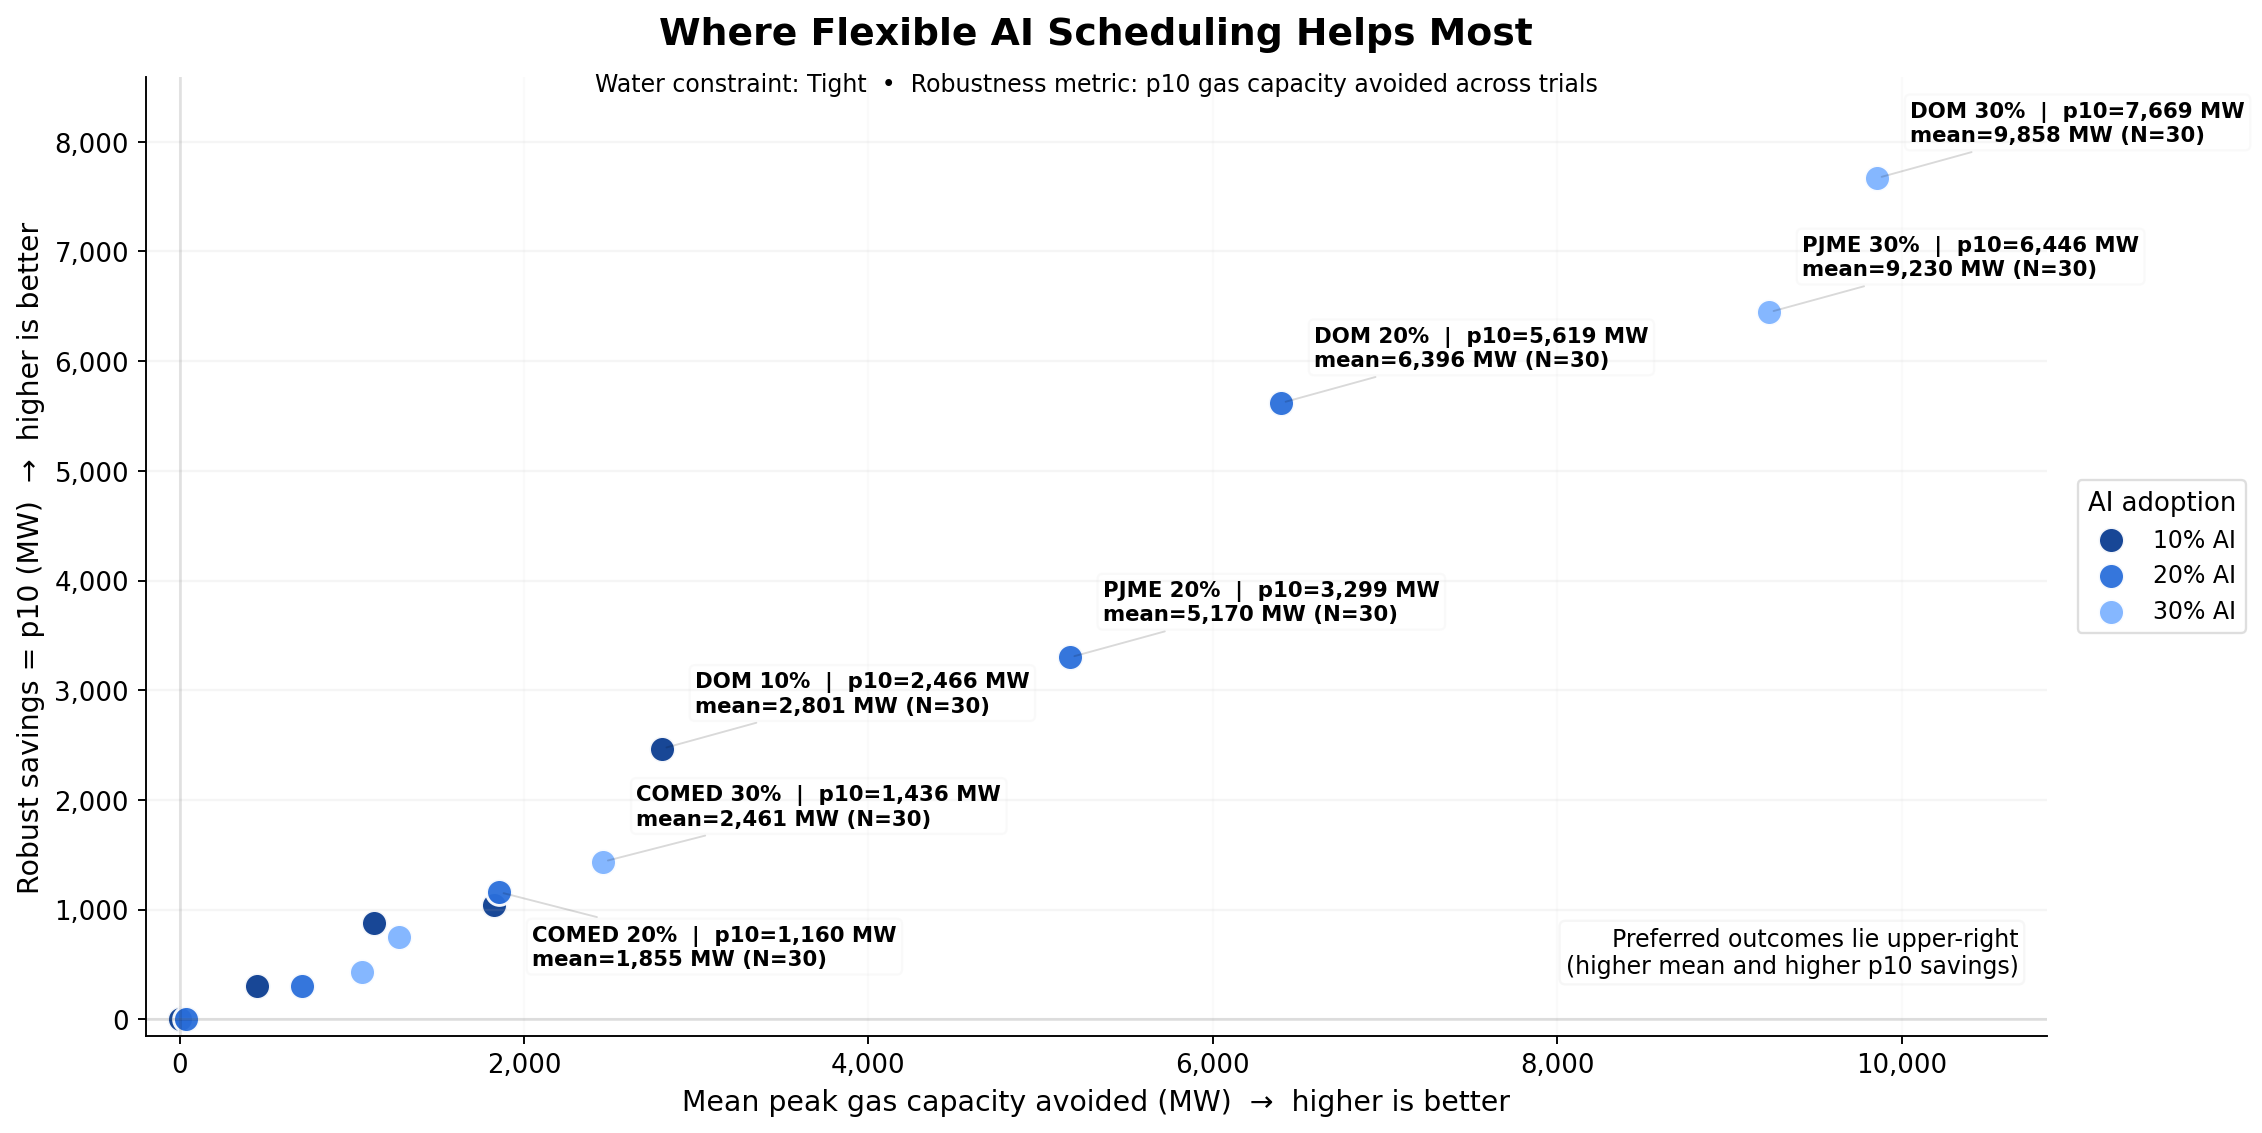

In [102]:
# @title Where Flexible Scheduling Helps Most (Mean vs Reliability)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def plot_where_scheduling_helps_most_poster(
    stats: pd.DataFrame,
    *,
    water_level: str = "Tight",
    reliability_q: float = 0.10,      # 0.10 => p10
    ai_fracs: list[float] | None = None,
    label_top_k: int = 7,             # label fewer = cleaner
    figsize=(13.5, 6.8),
    dpi=170,
):
    """
    Expects `stats` with columns:
      region, ai_fraction, n_trials, mean_saved_mw, reliable_saved_mw
    where reliable_saved_mw is the q-quantile (e.g., p10 when q=0.10).
    """

    df = stats.copy()
    df["region"] = df["region"].astype(str).str.strip()
    for c in ["ai_fraction","n_trials","mean_saved_mw","reliable_saved_mw"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["region","ai_fraction","n_trials","mean_saved_mw","reliable_saved_mw"])
    if df.empty:
        raise ValueError("stats is empty after cleanup.")

    if ai_fracs is None:
        ai_fracs = sorted(df["ai_fraction"].unique().tolist())
    else:
        ai_fracs = [float(a) for a in ai_fracs]
        df = df[df["ai_fraction"].isin(ai_fracs)].copy()

    # ---------------- style ----------------
    plt.rcParams.update({
        "font.size": 11,
        "axes.titlesize": 16,
        "axes.labelsize": 12,
        "axes.titleweight": "semibold",
        "legend.fontsize": 10,
    })

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    ax.set_facecolor("white")
    ax.grid(True, axis="y", alpha=0.12, linewidth=1.0)
    ax.grid(True, axis="x", alpha=0.06, linewidth=0.9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    comma = FuncFormatter(lambda x, pos: f"{int(x):,}")
    ax.xaxis.set_major_formatter(comma)
    ax.yaxis.set_major_formatter(comma)

    # scientific naming: p10
    p_label = f"p{int(round(100*reliability_q))}"  # e.g., p10
    ax.set_title("Where Flexible AI Scheduling Helps Most", pad=14)
    ax.text(
        0.5, 0.98,
        f"Water constraint: {water_level}  •  Robustness metric: {p_label} gas capacity avoided across trials",
        transform=ax.transAxes, ha="center", va="bottom",
        fontsize=10, color="#000000"
    )

    ax.set_xlabel("Mean peak gas capacity avoided (MW)  →  higher is better")
    ax.set_ylabel(f"Robust savings = {p_label} (MW)  →  higher is better")

    # axis bounds (tight, poster-friendly)
    xmax = float(df["mean_saved_mw"].max())
    ymax = float(df["reliable_saved_mw"].max())
    ax.set_xlim(left=min(-0.02*xmax, -50), right=1.10*xmax)
    ax.set_ylim(bottom=min(-0.02*ymax, -50), top=1.12*ymax)

    # subtle reference lines
    ax.axhline(0, color="black", alpha=0.10, linewidth=1.2)
    ax.axvline(0, color="black", alpha=0.10, linewidth=1.2)

    # # marker/colour map (restrained)
    # markers = ["o","s","D","^","v","P","X"]
    # colors  = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"]
    # marker_map = {ai_fracs[i]: markers[i % len(markers)] for i in range(len(ai_fracs))}
    # color_map  = {ai_fracs[i]: colors[i % len(colors)] for i in range(len(ai_fracs))}

    # all circles, same-hue shades (dark -> light as AI increases)
    marker_map = {a: "o" for a in ai_fracs}

    # pick one hue and 3 shades (edit if you want different blue family)
    shade_cycle = ["#0b3d91", "#2a6fdb", "#7fb3ff", "#cfe3ff"]  # dark -> light
    color_map = {ai_fracs[i]: shade_cycle[i % len(shade_cycle)] for i in range(len(ai_fracs))}



    # plot points by AI level
    for a in ai_fracs:
        sub = df[np.isclose(df["ai_fraction"], float(a), atol=1e-9)].copy()
        if sub.empty:
            continue
        ax.scatter(
            sub["mean_saved_mw"], sub["reliable_saved_mw"],
            s=120, marker="o",
            color=color_map[a], edgecolor="white", linewidth=1.2,
            alpha=0.95, label=f"{int(round(a*100))}% AI"
        )

    # ---- non-overlapping label placement (tries multiple offsets) ----
    fig.canvas.draw()  # ensure renderer exists
    renderer = fig.canvas.get_renderer()
    placed_bboxes = []

    # choose which points to label (top by robust then mean)
    df_rank = df.sort_values(["reliable_saved_mw","mean_saved_mw"], ascending=False).head(int(label_top_k))

    # candidate offsets in points (try many directions)
    candidates = [
        (14, 14), (14, -14), (-14, 14), (-14, -14),
        (24, 0), (-24, 0), (0, 24), (0, -24),
        (32, 16), (32, -16), (-32, 16), (-32, -16),
        (44, 0), (-44, 0)
    ]

    def label_text(row):
        reg = row["region"]
        a = int(round(float(row["ai_fraction"])*100))
        n = int(row["n_trials"])
        p10 = float(row["reliable_saved_mw"])
        mean = float(row["mean_saved_mw"])
        # concise + scientific
        return f"{reg} {a}%  |  {p_label}={p10:,.0f} MW\nmean={mean:,.0f} MW (N={n})"

    for _, r in df_rank.iterrows():
        x0 = float(r["mean_saved_mw"])
        y0 = float(r["reliable_saved_mw"])

        # Try offsets until we find a non-overlapping bbox
        placed = False
        for (dx, dy) in candidates:
            ann = ax.annotate(
                label_text(r),
                xy=(x0, y0),
                xytext=(dx, dy),
                textcoords="offset points",
                ha="left" if dx >= 0 else "right",
                va="bottom" if dy >= 0 else "top",
                fontsize=9,
                fontweight="semibold",
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#dddddd", alpha=0.15),
                arrowprops=dict(arrowstyle="-", color="#000000", alpha=0.15, linewidth=0.8),
                zorder=10
            )

            fig.canvas.draw()
            bb = ann.get_window_extent(renderer=renderer).expanded(1.02, 1.10)

            # check overlap with previously placed labels
            if any(bb.overlaps(prev) for prev in placed_bboxes):
                ann.remove()
                continue

            placed_bboxes.append(bb)
            placed = True
            break

        # If we couldn't place it cleanly, skip the label (clean > clutter)
        if not placed:
            pass

    # clean “best region” cue (scientific phrasing)
    ax.text(
        0.985, 0.06,
        "Preferred outcomes lie upper-right\n(higher mean and higher p10 savings)",
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=10, color="#000000",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#dddddd", alpha=0.25),
    )

    # legend outside plot (clean)
    leg = ax.legend(
        title="AI adoption",
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=True, framealpha=0.95
    )
    leg.get_frame().set_edgecolor("#dddddd")

    plt.tight_layout()
    return fig, ax


# ---- USAGE ----
fig, ax = plot_where_scheduling_helps_most_poster(
    stats,
    water_level="Tight",
    reliability_q=0.10,
    ai_fracs=[0.10, 0.20, 0.30],
    label_top_k=7
)
plt.show()


# Slightly BEtter OLD Charts

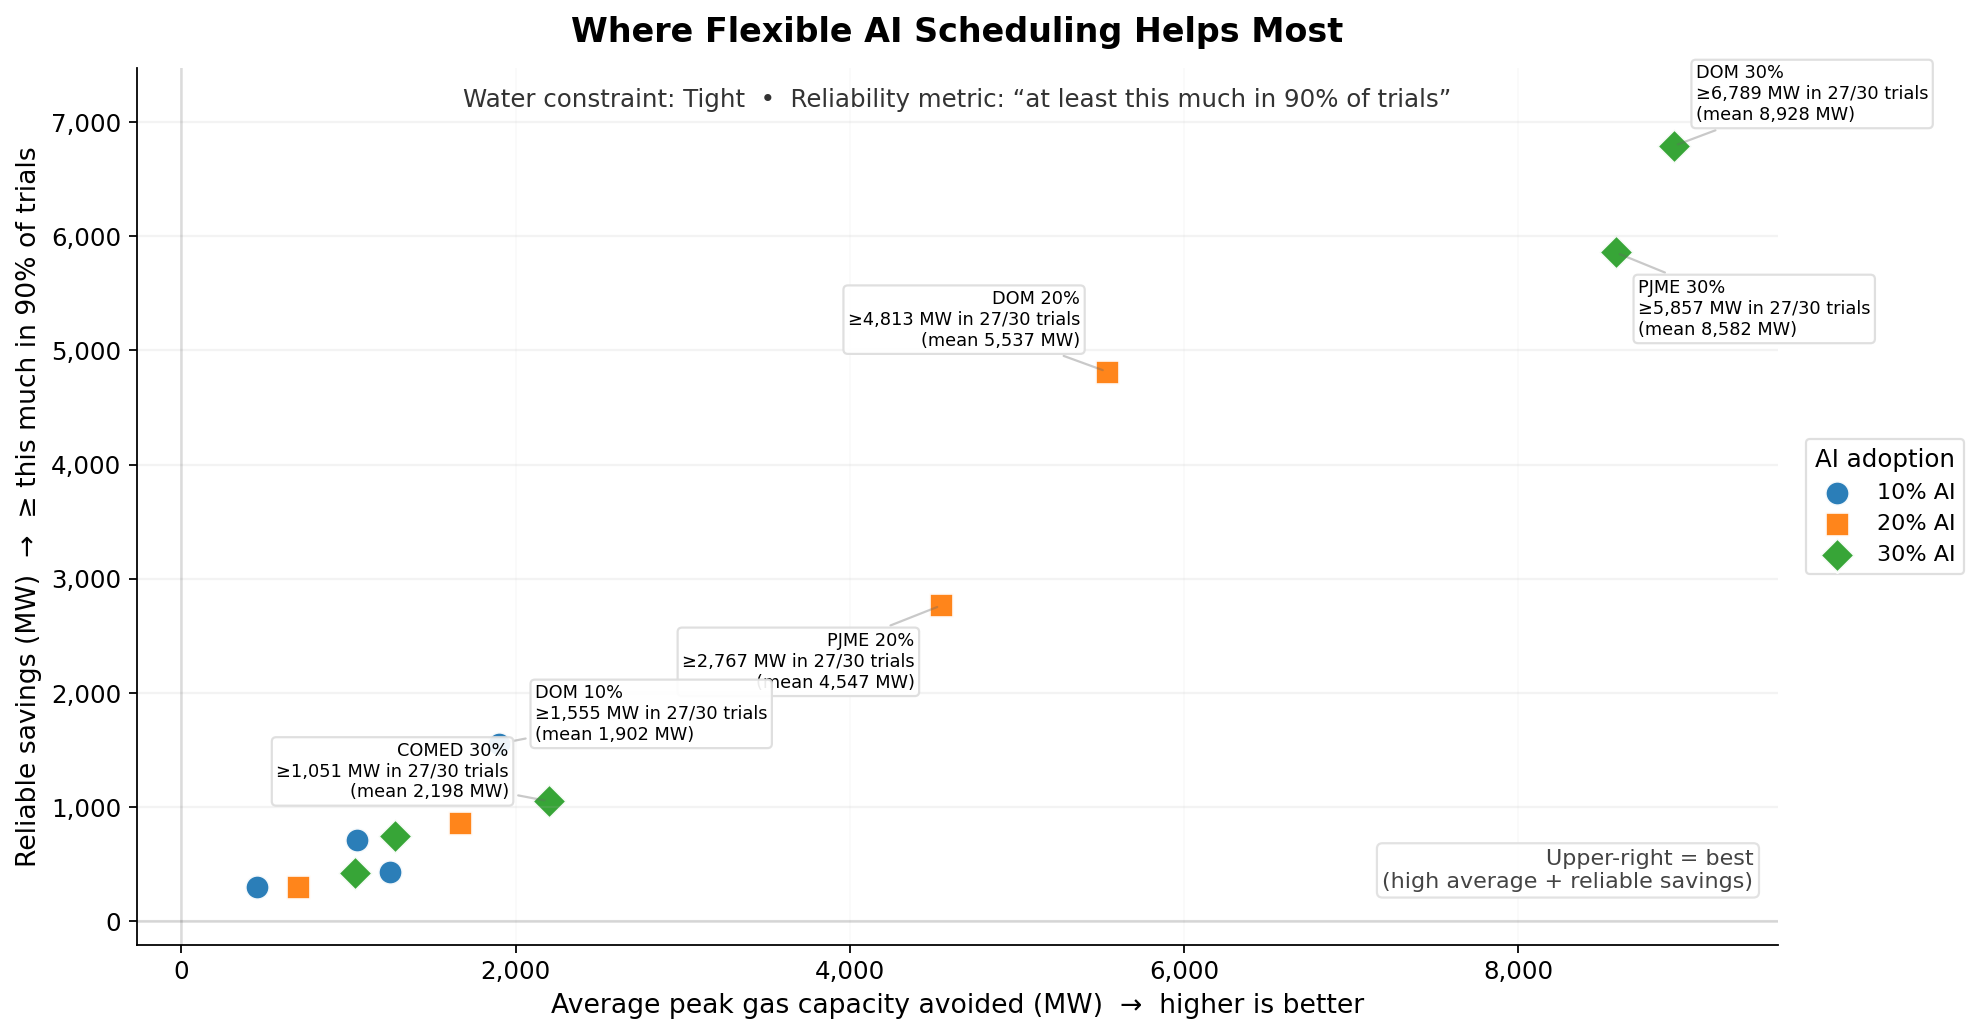

In [78]:
# @title Poster-ready: Where Flexible Scheduling Helps Most (Mean vs Reliability)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def plot_where_scheduling_helps_most_poster(
    stats: pd.DataFrame,
    *,
    water_level: str = "Tight",
    reliability_q: float = 0.10,     # 0.10 => 90% guarantee
    ai_fracs: list[float] | None = None,
    label_top_k: int = 6,            # label only top-k to avoid clutter
    figsize=(12.5, 6.6),
    dpi=160,
):
    """
    Expects `stats` with at least:
      region, ai_fraction, n_trials, mean_saved_mw, reliable_saved_mw
    Optional:
      baseline_median_mw, p_pos
    """

    df = stats.copy()
    df["region"] = df["region"].astype(str).str.strip()
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["mean_saved_mw"] = pd.to_numeric(df["mean_saved_mw"], errors="coerce")
    df["reliable_saved_mw"] = pd.to_numeric(df["reliable_saved_mw"], errors="coerce")
    df["n_trials"] = pd.to_numeric(df["n_trials"], errors="coerce")

    df = df.dropna(subset=["region","ai_fraction","mean_saved_mw","reliable_saved_mw","n_trials"])
    if df.empty:
        raise ValueError("stats is empty after cleanup.")

    if ai_fracs is None:
        ai_fracs = sorted(df["ai_fraction"].unique().tolist())
    else:
        ai_fracs = [float(a) for a in ai_fracs]
        df = df[df["ai_fraction"].isin(ai_fracs)].copy()

    # ---------- Styling (clean + professional) ----------
    plt.rcParams.update({
        "font.size": 11,
        "axes.titlesize": 15,
        "axes.labelsize": 12,
        "axes.titleweight": "semibold",
        "axes.labelweight": "regular",
        "legend.fontsize": 10,
    })

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    ax.set_facecolor("white")

    # light grid (y stronger than x)
    ax.grid(True, axis="y", alpha=0.14, linewidth=1.0)
    ax.grid(True, axis="x", alpha=0.06, linewidth=0.8)

    # remove top/right spines for a cleaner look
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # format ticks with commas (MW)
    fmt = FuncFormatter(lambda x, pos: f"{int(x):,}")
    ax.xaxis.set_major_formatter(fmt)
    ax.yaxis.set_major_formatter(fmt)

    # ---------- Plot points ----------
    # Use consistent marker shapes per AI level (no chaotic colors)
    marker_map = {ai_fracs[i]: m for i, m in enumerate(["o","s","D","^","v","P","X"][:len(ai_fracs)])}

    # A restrained “presentation” palette: one hue per AI level (still readable)
    # (If you truly want monochrome, set all to the same color.)
    color_map = {
        ai_fracs[i]: c for i, c in enumerate(["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"][:len(ai_fracs)])
    }

    # reference lines (subtle)
    ax.axhline(0, color="black", alpha=0.12, linewidth=1.2)
    ax.axvline(0, color="black", alpha=0.12, linewidth=1.2)

    # draw points grouped by AI
    for a in ai_fracs:
        sub = df[np.isclose(df["ai_fraction"], float(a), atol=1e-9)].copy()
        if sub.empty:
            continue

        ax.scatter(
            sub["mean_saved_mw"], sub["reliable_saved_mw"],
            s=120,
            marker=marker_map.get(float(a), "o"),
            color=color_map.get(float(a), "#1f77b4"),
            edgecolor="white",
            linewidth=1.2,
            alpha=0.95,
            label=f"{int(round(a*100))}% AI"
        )

    # ---------- Titles / subtitle ----------
    q_pct = int(round(100*(1.0 - reliability_q)))
    ax.set_title(
        "Where Flexible AI Scheduling Helps Most",
        pad=12
    )
    ax.text(
        0.5, 0.95,
        f"Water constraint: {water_level}  •  Reliability metric: “at least this much in {q_pct}% of trials”",
        transform=ax.transAxes, ha="center", va="bottom",
        fontsize=11, color="#333333"
    )

    ax.set_xlabel("Average peak gas capacity avoided (MW)  →  higher is better")
    ax.set_ylabel(f"Reliable savings (MW)  →  ≥ this much in {q_pct}% of trials")

    # ---------- Smart bounds (tight, not floaty) ----------
    xmax = float(np.nanmax(df["mean_saved_mw"]))
    ymax = float(np.nanmax(df["reliable_saved_mw"]))
    ax.set_xlim(left=min(-0.03*xmax, -50), right=1.07*xmax)
    ax.set_ylim(bottom=min(-0.03*ymax, -50), top=1.10*ymax)

    # ---------- Label only top-k (declutters) ----------
    # Define “best” as high reliability, then high mean
    df_rank = df.sort_values(["reliable_saved_mw","mean_saved_mw"], ascending=False).reset_index(drop=True)
    top = df_rank.head(int(label_top_k)).copy()

    # Offsets that alternate so labels don't pile up
    offsets = [(10, 10), (10, -12), (-12, 10), (-12, -12), (16, 0), (-18, 0)]
    def one_label(row, i):
        reg = row["region"]
        a = int(round(float(row["ai_fraction"])*100))
        n = int(row["n_trials"])
        # judge-friendly stat:
        # “≥X MW in 27/30 trials”  (assuming q=0.10)
        k_good = int(np.ceil((1.0 - reliability_q) * n))
        rel = float(row["reliable_saved_mw"])
        mean = float(row["mean_saved_mw"])
        return f"{reg} {a}%\n≥{rel:,.0f} MW in {k_good}/{n} trials\n(mean {mean:,.0f} MW)"

    for i, (_, r) in enumerate(top.iterrows()):
        dx, dy = offsets[i % len(offsets)]
        ax.annotate(
            one_label(r, i),
            xy=(r["mean_saved_mw"], r["reliable_saved_mw"]),
            xytext=(dx, dy),
            textcoords="offset points",
            ha="left" if dx >= 0 else "right",
            va="bottom" if dy >= 0 else "top",
            fontsize=8,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#dddddd", alpha=0.92),
            arrowprops=dict(arrowstyle="-", color="#666666", alpha=0.35, linewidth=1.0)
        )

    # ---------- “Best zone” cue (subtle, professional) ----------
    ax.text(
        0.985, 0.06,
        "Upper-right = best\n(high average + reliable savings)",
        transform=ax.transAxes,
        ha="right", va="bottom",
        fontsize=10, color="#444444",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#dddddd", alpha=0.85),
    )

    # ---------- Legend (clean placement) ----------
    leg = ax.legend(
        title="AI adoption",
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=True,
        framealpha=0.92
    )
    leg.get_frame().set_edgecolor("#dddddd")

    plt.tight_layout()
    return fig, ax


# --- USAGE ---
fig, ax = plot_where_scheduling_helps_most_poster(
    stats,
    water_level="Tight",
    reliability_q=0.10,
    ai_fracs=[0.10, 0.20, 0.30],
    label_top_k=6
)
plt.show()


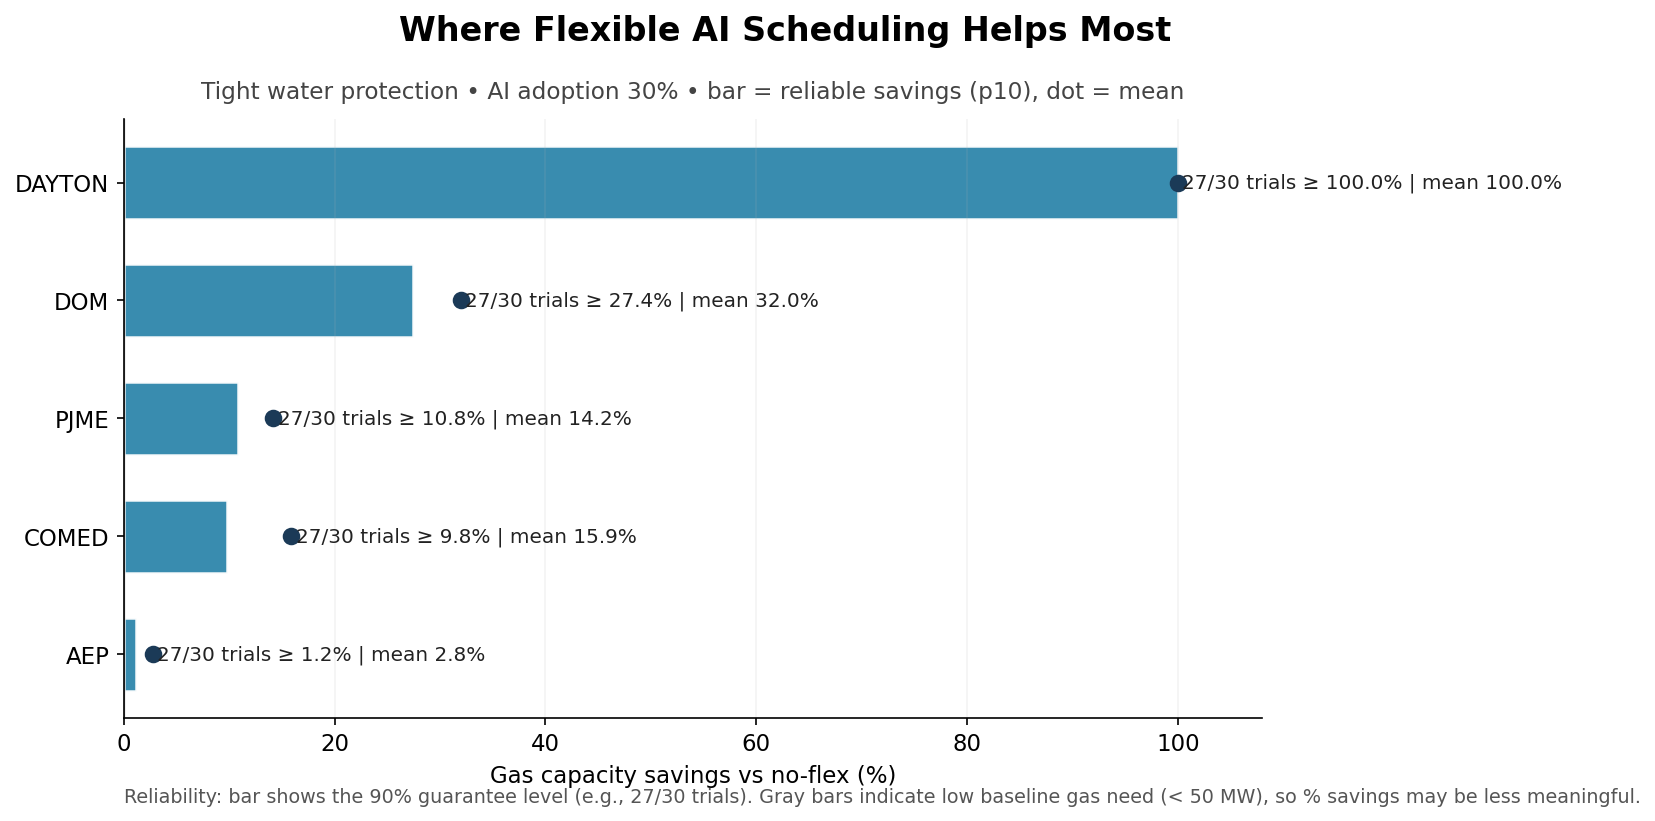

In [69]:
# @title PRO CHART: Where scheduling helps most (mean vs reliability)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_region_impact_ranking_pro(
    out: pd.DataFrame,
    ai_frac: float = 0.20,
    water_band: str = "Tight",        # Tight / Med / Loose
    q_reliable: float = 10.0,         # 10th percentile -> "90% of trials >= p10"
    min_trials: int = 10,
    min_baseline_gas_mw: float = 50.0,  # if baseline gas is tiny, % can be misleading
    exclude_low_baseline: bool = False
):
    df = out.copy()
    df["region"] = df["region"].astype(str).str.strip()
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["trial"] = pd.to_numeric(df["trial"], errors="coerce")
    df["eps_idx"] = pd.to_numeric(df["eps_idx"], errors="coerce")
    df["gas_improve_pct_vs_noflex"] = pd.to_numeric(df["gas_improve_pct_vs_noflex"], errors="coerce")
    df["gas_no_flex_mw"] = pd.to_numeric(df.get("gas_no_flex_mw", np.nan), errors="coerce")

    # eps_frac
    if "eps_frac" in df.columns:
        df["eps_frac"] = pd.to_numeric(df["eps_frac"], errors="coerce")
    else:
        gmax = df.groupby(["region","ai_fraction","trial"])["eps_idx"].transform("max").replace(0, np.nan)
        df["eps_frac"] = df["eps_idx"] / gmax

    df = df[np.isclose(df["ai_fraction"], float(ai_frac), atol=1e-8)].copy()
    df = df.dropna(subset=["region","trial","eps_frac","gas_improve_pct_vs_noflex"])

    # water band
    df["water_band"] = pd.cut(df["eps_frac"], [-np.inf, 1/3, 2/3, np.inf], labels=["Tight","Med","Loose"])
    df = df[df["water_band"].astype(str) == str(water_band)].copy()
    if df.empty:
        raise ValueError(f"No data found for ai_frac={ai_frac} and water_band={water_band}.")

    # per-trial stats (avoid overweighting eps points)
    per_trial = (
        df.groupby(["region","trial"], as_index=False)
          .agg(
              pct_sav=("gas_improve_pct_vs_noflex","mean"),
              baseline_gas=("gas_no_flex_mw","first")  # constant within trial
          )
    )

    # region summary
    def pctl(x, q):
        x = np.asarray(x, dtype=float)
        return float(np.percentile(x, q)) if len(x) else np.nan

    summary = (
        per_trial.groupby("region", as_index=False)
                 .agg(
                     mean_sav=("pct_sav","mean"),
                     p10_sav=("pct_sav", lambda x: pctl(x, q_reliable)),
                     n_trials=("trial","nunique"),
                     baseline_gas_mean=("baseline_gas","mean")
                 )
    ).dropna(subset=["mean_sav","p10_sav","n_trials"])

    # optionally exclude regions where baseline gas is basically 0 (no constraint to shave)
    if exclude_low_baseline:
        summary = summary[summary["baseline_gas_mean"] >= float(min_baseline_gas_mw)].copy()

    summary = summary[summary["n_trials"] >= int(min_trials)].copy()
    if summary.empty:
        raise ValueError("No regions left after filtering (try lowering min_trials or baseline threshold).")

    # sort by reliability first (p10), then mean
    summary = summary.sort_values(["p10_sav","mean_sav"], ascending=True).reset_index(drop=True)

    # ---- styling ----
    fig, ax = plt.subplots(figsize=(10.6, 5.6), dpi=150)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    y = np.arange(len(summary))

    # colors (muted, poster-friendly)
    BAR = "#2E86AB"       # muted blue
    DOT = "#1B3A57"       # darker navy
    LOW = "#B0B0B0"       # gray for low-baseline cases

    # gray-out regions with tiny baseline gas (even if not excluded)
    is_low = summary["baseline_gas_mean"] < float(min_baseline_gas_mw)
    bar_colors = [LOW if b else BAR for b in is_low]

    # Bars = p10 (reliable)
    ax.barh(y, summary["p10_sav"], height=0.62, color=bar_colors, edgecolor="white", linewidth=1.2, alpha=0.95)

    # Dots = mean
    ax.scatter(summary["mean_sav"], y, s=55, color=DOT, zorder=3)

    # Labels
    for i, r in summary.iterrows():
        n = int(r["n_trials"])
        k = int(np.ceil(0.90 * n))
        label = f"{k}/{n} trials ≥ {r['p10_sav']:.1f}% | mean {r['mean_sav']:.1f}%"
        if r["baseline_gas_mean"] < float(min_baseline_gas_mw):
            label += f"  (baseline gas ≈ {r['baseline_gas_mean']:.0f} MW)"

        ax.text(
            max(r["mean_sav"], r["p10_sav"]) + 0.4, i,
            label, va="center", ha="left", fontsize=9.6, color="#222222"
        )

    # axes
    ax.axvline(0, color="#666666", lw=1.1, alpha=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(summary["region"], fontsize=11)
    ax.set_xlabel("Gas capacity savings vs no-flex (%)", fontsize=11)

    xmax = float(max(summary["mean_sav"].max(), summary["p10_sav"].max()) + 8.0)
    ax.set_xlim(0, xmax)

    # title/subtitle (clean, not “lab-y”)
    fig.suptitle("Where Flexible AI Scheduling Helps Most", fontsize=16, fontweight="bold", y=0.98)
    ax.set_title(
        f"{water_band} water protection • AI adoption {int(ai_frac*100)}% • bar = reliable savings (p10), dot = mean",
        fontsize=11.2, color="#444444", pad=10
    )

    # grid + spines
    ax.grid(True, axis="x", alpha=0.15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # small note
    ax.text(
        0.0, -0.14,
        f"Reliability: bar shows the {int(100-q_reliable)}% guarantee level (e.g., 27/30 trials). "
        f"Gray bars indicate low baseline gas need (< {min_baseline_gas_mw:.0f} MW), so % savings may be less meaningful.",
        transform=ax.transAxes, fontsize=9.2, color="#555555"
    )

    plt.tight_layout()
    return fig, ax, summary

# Example:
fig, ax, summary = plot_region_impact_ranking_pro(out, ai_frac=0.30, water_band="Tight")
plt.show()


/tmp/ipython-input-1567756972.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sub.groupby(["trial", "water_bin"], as_index=False)
/tmp/ipython-input-1567756972.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_trial.groupby("water_bin", as_index=False)


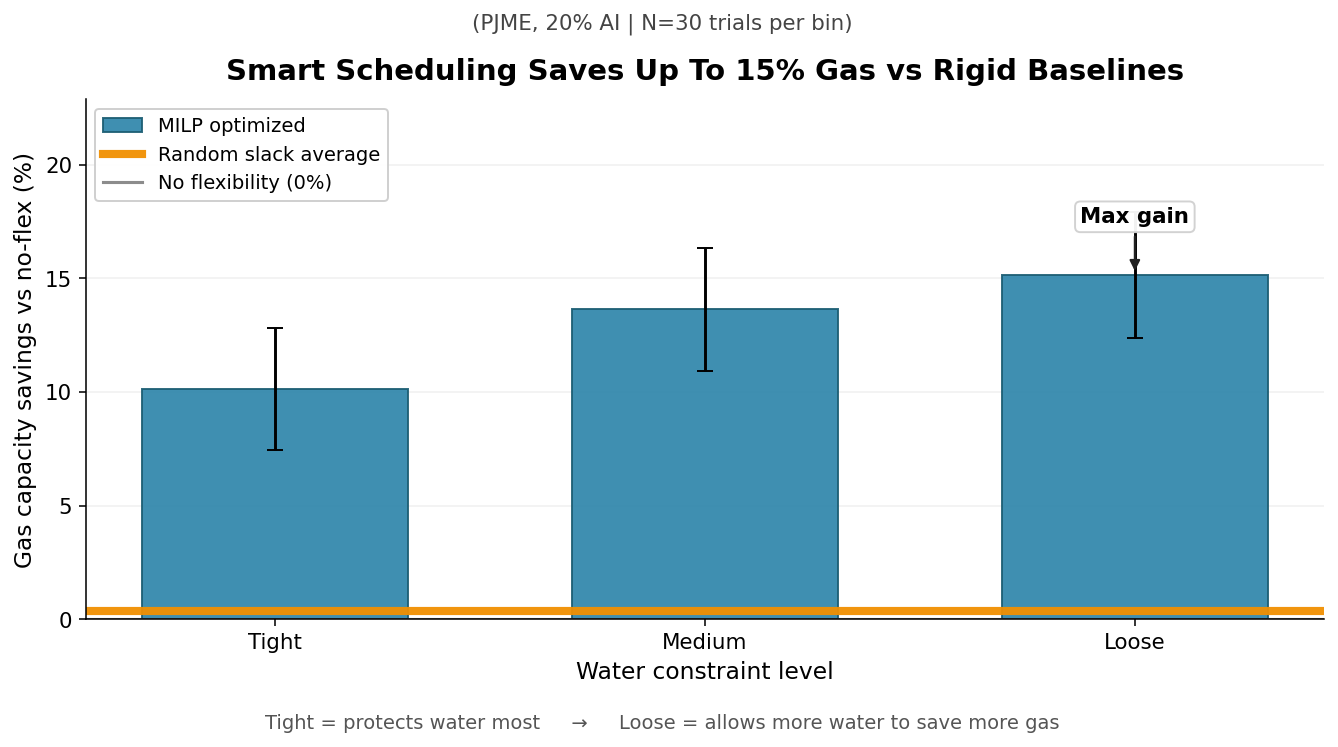

In [62]:
# @title 9A (Poster Style). Smart Scheduling vs Baselines (clean, single axis)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits_poster(
    df: pd.DataFrame,
    region: str = "PJME",
    ai_frac: float = 0.20,
    bins: Tuple[str, str, str] = ("Tight", "Medium", "Loose"),
):
    # ---------- Data prep ----------
    work = df.copy()
    work["region"] = work["region"].astype(str).str.strip()

    need = ["ai_fraction", "trial", "eps_idx", "gas_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]
    missing = [c for c in need if c not in work.columns]
    if missing:
        raise ValueError(f"df missing required columns: {missing}")

    for c in need:
        work[c] = pd.to_numeric(work[c], errors="coerce")

    sub = work[
        (work["region"] == str(region)) &
        np.isclose(work["ai_fraction"], float(ai_frac), atol=1e-8)
    ].dropna(subset=["trial", "eps_idx", "gas_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]).copy()

    if sub.empty:
        raise ValueError(f"No valid rows for region={region}, ai_frac={ai_frac}")

    # Derive eps_frac if needed, then bin into Tight/Medium/Loose
    if "eps_frac" in sub.columns:
        sub["eps_frac"] = pd.to_numeric(sub["eps_frac"], errors="coerce")
    else:
        max_eps = sub.groupby("trial")["eps_idx"].transform("max").replace(0, np.nan)
        sub["eps_frac"] = sub["eps_idx"] / max_eps

    sub = sub.dropna(subset=["eps_frac"]).copy()
    sub["water_bin"] = pd.cut(
        sub["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=list(bins)
    )
    sub = sub.dropna(subset=["water_bin"]).copy()

    # Correct aggregation: per-trial mean inside each bin, then across trials
    per_trial = (
        sub.groupby(["trial", "water_bin"], as_index=False)
           .agg(gas_sav=("gas_improve_pct_vs_noflex", "mean"))
    )
    stats = (
        per_trial.groupby("water_bin", as_index=False)
                 .agg(
                     gas_mean=("gas_sav", "mean"),
                     gas_std=("gas_sav", "std"),
                     n_trials=("trial", "nunique")
                 )
    )
    stats["water_bin"] = pd.Categorical(stats["water_bin"], categories=list(bins), ordered=True)
    stats = stats.sort_values("water_bin").reset_index(drop=True)
    stats["gas_std"] = stats["gas_std"].fillna(0.0)

    # Random slack baseline (one value across trials)
    trial_base = sub.groupby("trial")[["gas_no_flex_mw", "gas_random_mw"]].first().dropna()
    random_pct = 100.0 * (trial_base["gas_no_flex_mw"] - trial_base["gas_random_mw"]) / trial_base["gas_no_flex_mw"]
    r_mean = float(random_pct.mean())

    # ---------- Poster styling ----------
    plt.rcParams.update({
        "font.size": 11,
        "axes.titlesize": 15,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

    fig, ax = plt.subplots(figsize=(10.2, 6.0), dpi=140)

    x = np.arange(len(stats))
    bar_color = "#2E86AB"   # muted blue
    bar_edge  = "#1C5D73"
    rand_color = "#F18F01"  # orange

    # Bars (MILP)
    bars = ax.bar(
        x, stats["gas_mean"],
        yerr=stats["gas_std"],
        width=0.62,
        color=bar_color,
        edgecolor=bar_edge,
        linewidth=1.0,
        alpha=0.92,
        capsize=4,
        label="MILP optimized"
    )

    # Random slack: thick line (clean)
    rand_line = ax.axhline(
        r_mean, color=rand_color, lw=4.2, alpha=0.95,
        label="Random slack average"
    )

    # 0% reference: thin neutral line
    zero_line = ax.axhline(0, color="#666666", lw=1.6, alpha=0.75, label="No flexibility (0%)")

    # Grid: subtle
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", alpha=0.16, linewidth=0.9)
    ax.grid(False, axis="x")

    # X labels: human readable
    ax.set_xticks(x)
    ax.set_xticklabels([str(b) for b in stats["water_bin"]])

    ax.set_xlabel("Water constraint level")
    ax.set_ylabel("Gas capacity savings vs no-flex (%)")

    # Tight y-limits (no dead space)
    top = float(np.max(stats["gas_mean"] + stats["gas_std"])) if len(stats) else 0.0
    y_max = max(top, r_mean) * 1.22 + 1.0
    ax.set_ylim(0, y_max)

    # Title + subtitle (less “stacked”)
    max_gain = float(np.nanmax(stats["gas_mean"])) if len(stats) else float("nan")
    ax.set_title(
        f"Smart Scheduling Saves Up To {max_gain:.0f}% Gas vs Rigid Baselines",
        pad=10, fontweight="semibold"
    )
    fig.text(
        0.5, 0.905,
        f"({str(region).upper()}, {int(round(ai_frac*100))}% AI | N={int(stats['n_trials'].max()) if len(stats) else '—'} trials per bin)",
        ha="center", va="top", fontsize=11, color="#444444"
    )

    # Footnote (clean, centered)
    fig.text(
        0.5, 0.06,
        "Tight = protects water most     →     Loose = allows more water to save more gas",
        ha="center", va="center", fontsize=10, color="#555555"
    )

    # Annotation on max bar (compact, not floating)
    imax = int(np.nanargmax(stats["gas_mean"].to_numpy()))
    y = float(stats["gas_mean"].iloc[imax])
    ax.annotate(
        "Max gain",
        xy=(imax, y),
        xytext=(imax, y + 0.10*y_max),
        ha="center",
        arrowprops=dict(arrowstyle="-|>", lw=1.1, color="#222222"),
        fontsize=11,
        fontweight="semibold",
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="#d0d0d0", alpha=0.95),
    )

    # Legend: reorder to match hierarchy (MILP, Random, 0%)
    handles, labels = ax.get_legend_handles_labels()
    order = [labels.index("MILP optimized"), labels.index("Random slack average"), labels.index("No flexibility (0%)")]
    ax.legend([handles[i] for i in order], [labels[i] for i in order],
              loc="upper left", frameon=True, framealpha=0.93, fontsize=10)

    plt.tight_layout(rect=[0.03, 0.08, 0.98, 0.88])
    return fig, ax, stats


# Usage:
fig, ax, stats = plot_flexibility_benefits_poster(out, region="PJME", ai_frac=0.20)
plt.show()


/tmp/ipython-input-3736970995.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipython-input-3736970995.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipython-input-3736970995.py:80: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


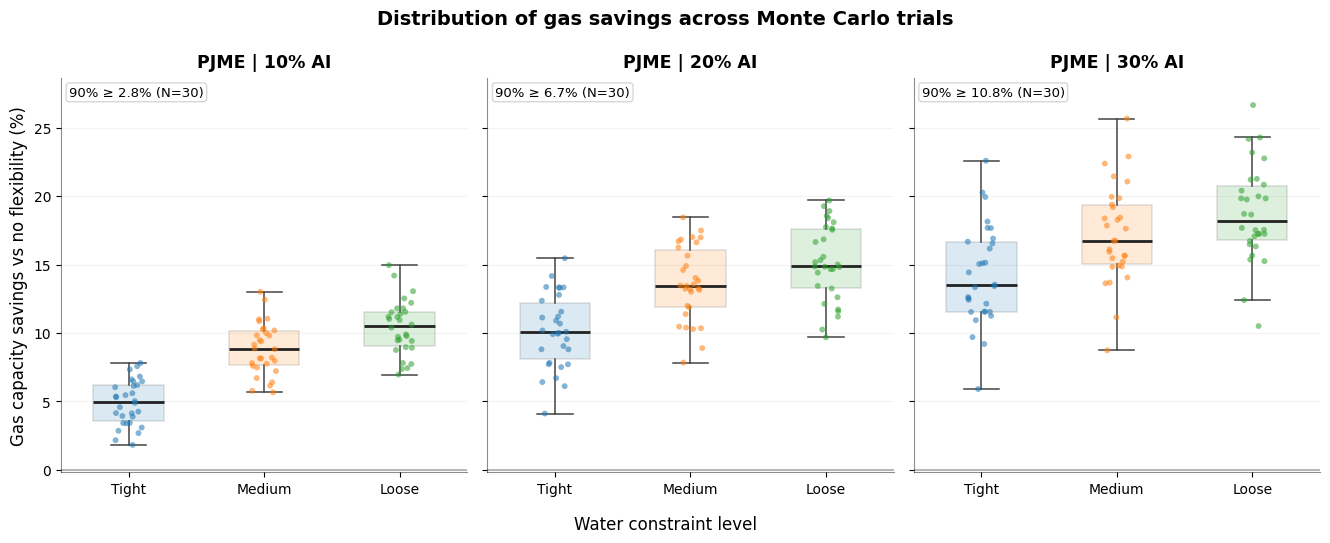

In [11]:
# @title Panel chart: Gas savings distribution for multiple AI fractions (side-by-side)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _prepare_gas_savings_distribution_data(out: pd.DataFrame, region: str, ai_frac: float):
    df = out.copy()
    df["region"] = df["region"].astype(str).str.strip()

    for c in ["ai_fraction", "trial", "gas_improve_pct_vs_noflex"]:
        if c not in df.columns:
            raise ValueError(f"Missing required column: {c}")
        df[c] = pd.to_numeric(df[c], errors="coerce")

    # eps_frac preferred; else derive from eps_idx within each trial
    if "eps_frac" not in df.columns or df["eps_frac"].isna().all():
        if "eps_idx" not in df.columns:
            raise ValueError("Need eps_frac or eps_idx to create Tight/Med/Loose bins.")
        df["eps_idx"] = pd.to_numeric(df["eps_idx"], errors="coerce")
        max_eps = df.groupby(["region", "ai_fraction", "trial"])["eps_idx"].transform("max")
        df["eps_frac"] = df["eps_idx"] / max_eps.replace(0, np.nan)
    else:
        df["eps_frac"] = pd.to_numeric(df["eps_frac"], errors="coerce")

    sub = df[
        (df["region"] == str(region)) &
        np.isclose(df["ai_fraction"], float(ai_frac), atol=1e-9)
    ].dropna(subset=["trial", "eps_frac", "gas_improve_pct_vs_noflex"]).copy()

    if sub.empty:
        raise ValueError(f"No valid rows for region={region}, ai_frac={ai_frac}")

    sub["water_bin"] = pd.cut(
        sub["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=["Tight", "Medium", "Loose"]
    )
    sub = sub.dropna(subset=["water_bin"]).copy()
    sub["water_bin"] = sub["water_bin"].astype(str)

    # Per-trial mean within each bin
    per_trial = (
        sub.groupby(["trial", "water_bin"], as_index=False)
           .agg(gas_savings_pct=("gas_improve_pct_vs_noflex", "mean"))
    )

    order = ["Tight", "Medium", "Loose"]
    per_trial["water_bin"] = pd.Categorical(per_trial["water_bin"], categories=order, ordered=True)
    per_trial = per_trial.sort_values(["water_bin", "trial"]).reset_index(drop=True)

    data = []
    for b in order:
        vals = per_trial.loc[per_trial["water_bin"] == b, "gas_savings_pct"].to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]
        data.append(vals)

    # Robustness stats (p10 => 90% achieve >= p10)
    stats = []
    for b, vals in zip(order, data):
        if len(vals) == 0:
            stats.append({"water_bin": b, "n_trials": 0, "median": np.nan, "p10": np.nan})
        else:
            stats.append({
                "water_bin": b,
                "n_trials": int(len(vals)),
                "median": float(np.median(vals)),
                "p10": float(np.quantile(vals, 0.10)),
            })
    stats_df = pd.DataFrame(stats)

    return data, stats_df


def _draw_distribution_on_ax(ax, data, stats_df, *, title: str, show_points: bool = True):
    order = ["Tight", "Medium", "Loose"]
    box_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
    rng = np.random.default_rng(0)

    bp = ax.boxplot(
        data,
        labels=order,
        showfliers=False,
        widths=0.52,
        patch_artist=True,
        medianprops=dict(linewidth=2.0, color="#222222"),
        boxprops=dict(linewidth=1.1, color="#444444"),
        whiskerprops=dict(linewidth=1.1, color="#444444"),
        capprops=dict(linewidth=1.1, color="#444444"),
    )

    # Fill boxes lightly
    for patch, c in zip(bp["boxes"], box_colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.16)

    # Overlay points
    if show_points:
        for i, (vals, c) in enumerate(zip(data, box_colors), start=1):
            if len(vals) == 0:
                continue
            jitter = rng.uniform(-0.10, 0.10, size=len(vals))
            ax.scatter(
                np.full(len(vals), i) + jitter,
                vals,
                s=18,
                alpha=0.55,
                color=c,
                edgecolors="none",
                zorder=3
            )

    ax.axhline(0, color="#777777", lw=1.2, alpha=0.6)

    ax.set_title(title, fontsize=12.5, fontweight="semibold", pad=8)

    # light grid + clean spines
    ax.grid(True, axis="y", alpha=0.14, linewidth=0.8)
    ax.grid(False, axis="x")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_alpha(0.45)
    ax.spines["bottom"].set_alpha(0.45)

    # small callout inside each subplot (tight)
    tight_row = stats_df[stats_df["water_bin"] == "Tight"]
    if not tight_row.empty and np.isfinite(tight_row["p10"].iloc[0]):
        p10 = float(tight_row["p10"].iloc[0])
        ntr = int(tight_row["n_trials"].iloc[0])
        ax.text(
            0.02, 0.98,
            f"90% ≥ {p10:.1f}% (N={ntr})",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=9.5,
            bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="#d0d0d0", alpha=0.85)
        )

    return bp


def plot_gas_savings_distribution_panel(
    out: pd.DataFrame,
    region: str,
    ai_fracs,
    *,
    show_points: bool = True
):
    """
    One compact figure with side-by-side boxplots for multiple AI fractions.
    """
    ai_fracs = [float(a) for a in ai_fracs]

    # Prepare all data first so we can set a GLOBAL y-limit (prevents clipping + makes panels comparable)
    prepared = []
    all_vals = []
    for a in ai_fracs:
        data, stats_df = _prepare_gas_savings_distribution_data(out, region, a)
        prepared.append((a, data, stats_df))
        for v in data:
            if len(v) > 0:
                all_vals.append(v)

    if not all_vals:
        raise ValueError("No data to plot.")
    all_vals = np.concatenate(all_vals)

    # Global y-limits with padding
    lo = float(np.min(all_vals))
    hi = float(np.max(all_vals))
    pad = 0.08 * (hi - lo + 1e-9)
    y0, y1 = lo - pad, hi + pad

    # Create the panel
    fig, axes = plt.subplots(
        1, len(ai_fracs),
        figsize=(4.2*len(ai_fracs) + 0.8, 5.4),
        sharey=True
    )

    if len(ai_fracs) == 1:
        axes = [axes]

    for ax, (a, data, stats_df) in zip(axes, prepared):
        _draw_distribution_on_ax(
            ax, data, stats_df,
            title=f"{region.upper()} | {int(round(a*100))}% AI",
            show_points=show_points
        )
        ax.set_ylim(y0, y1)

    # Shared labels (only once)
    axes[0].set_ylabel("Gas capacity savings vs no flexibility (%)", fontsize=12)
    fig.supxlabel("Water constraint level", fontsize=12, y=0.02)

    fig.suptitle(
        "Distribution of gas savings across Monte Carlo trials",
        fontsize=14, fontweight="semibold", y=0.99
    )

    plt.tight_layout()
    return fig, axes


# --- Usage example ---
# Put the AI fractions you want side-by-side here:
fig, axes = plot_gas_savings_distribution_panel(out, region="PJME", ai_fracs=[0.10, 0.20, 0.30], show_points=True)
plt.show()


# Old Charts

In [ ]:
# @title 8. Pareto Frontier Statistics (Mean ± Std, N=trials)
out.groupby(["region","ai_fraction","eps_idx"]).size().head(20)
summary = (out.groupby(["region","ai_fraction","eps_idx"])
  .agg(
    epsilon_cap_mean=("epsilon_water_cap","mean"),
    epsilon_cap_std =("epsilon_water_cap","std"),

    # MILP outcomes (absolute)
    gas_peak_mw_mean=("gas_peak_mw","mean"),
    gas_peak_mw_std =("gas_peak_mw","std"),
    water_peak_m3h_mean=("water_peak_m3h","mean"),
    water_peak_m3h_std =("water_peak_m3h","std"),

    # baselines (absolute)
    gas_no_flex_mw_mean=("gas_no_flex_mw","mean"),
    water_no_flex_m3h_mean=("water_no_flex_m3h","mean"),
    gas_random_mw_mean=("gas_random_mw","mean"),
    water_random_m3h_mean=("water_random_m3h","mean"),

    # improvements (%)
    gas_improve_vs_noflex_mean=("gas_improve_pct_vs_noflex","mean"),
    gas_improve_vs_noflex_std =("gas_improve_pct_vs_noflex","std"),
    water_improve_vs_noflex_mean=("water_improve_pct_vs_noflex","mean"),
    water_improve_vs_noflex_std =("water_improve_pct_vs_noflex","std"),
  )
  .reset_index()
)

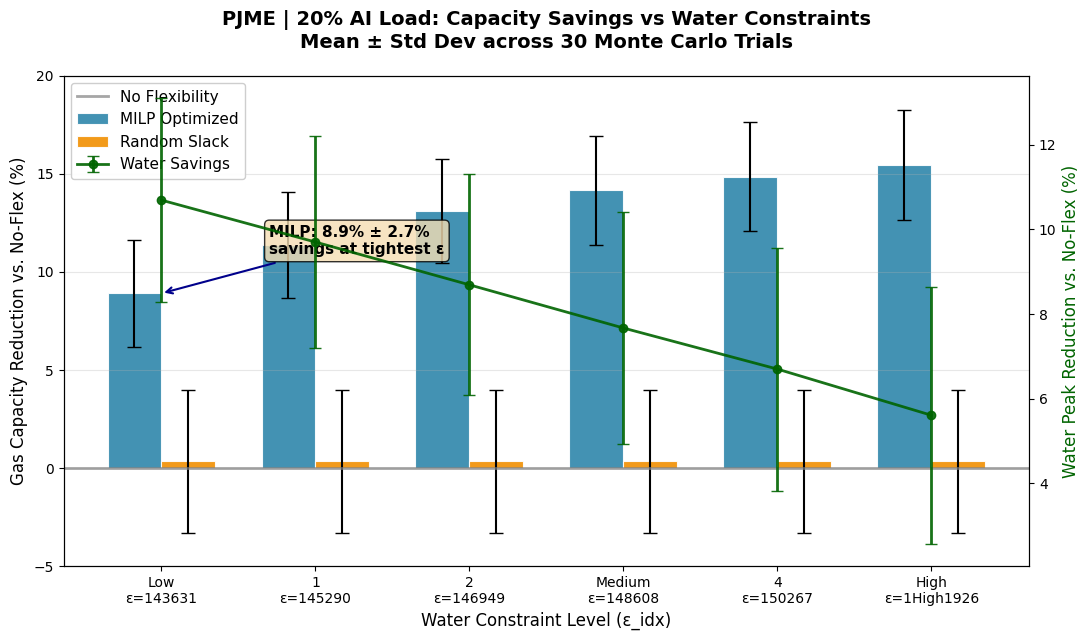

In [ ]:
# @title 9. AI flexibility vs. baselines across water constraints

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits(df: pd.DataFrame, region: str = "COMED", ai_frac: float = 0.1) -> Tuple[plt.Figure, plt.Axes, pd.DataFrame]:
    """
    AI flexibility vs. baselines across water constraints.

    X: Water cap levels (ε_idx)
    Primary Y: Gas capacity reduction % vs. no-flex (MILP | Random | 0% line)
    Secondary Y: Water reduction % vs. no-flex (MILP only)

    Expected columns: region, ai_fraction, eps_idx, epsilon_water_cap,
    gas_improve_pct_vs_noflex, water_improve_pct_vs_noflex, gas_no_flex_mw, gas_random_mw
    """

    # === DATA PREPARATION ===
    work_df = df.copy()
    work_df["region"] = work_df["region"].astype(str).str.strip()

    # Robust numeric conversion
    for col in ["ai_fraction", "eps_idx", "epsilon_water_cap", "gas_improve_pct_vs_noflex",
                "water_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

    # Filter with tolerance for floating point
    filtered = work_df[
        (work_df["region"] == region) &
        np.isclose(work_df["ai_fraction"], ai_frac, atol=1e-8)
    ].dropna(subset=['eps_idx', 'gas_improve_pct_vs_noflex', 'gas_no_flex_mw', 'gas_random_mw'])

    if filtered.empty:
        raise ValueError(f"No valid data for {region}, {ai_frac*100:.0f}% AI")

    # MILP statistics by ε_idx (mean ± std across trials)
    milp_stats = (filtered.groupby('eps_idx')
                 .agg({
                     'epsilon_water_cap': ['mean', 'std'],
                     'gas_improve_pct_vs_noflex': ['mean', 'std'],
                     'water_improve_pct_vs_noflex': ['mean', 'std'],
                     'trial': 'nunique'
                 })
                 .round(2)
                 .reset_index())
    milp_stats.columns = ['eps_idx', 'eps_mean', 'eps_std', 'gas_mean', 'gas_std',
                         'water_mean', 'water_std', 'n_trials']

    # Random baseline (constant across ε_idx)
    trial_baselines = filtered.groupby('trial')[['gas_no_flex_mw', 'gas_random_mw']].first().dropna()
    random_pct = 100 * (trial_baselines['gas_no_flex_mw'] - trial_baselines['gas_random_mw']) / trial_baselines['gas_no_flex_mw']
    milp_stats['random_mean'] = random_pct.mean()
    milp_stats['random_std'] = random_pct.std()

    # === PLOTTING ===
    fig, ax = plt.subplots(figsize=(11, 6.5))
    x = np.arange(len(milp_stats))
    width = 0.35

    # Gas capacity bars (primary axis)
    colors = ['#2E86AB', '#F18F01']  # Professional blue/orange
    ax.bar(x - width/2, milp_stats['gas_mean'], width, yerr=milp_stats['gas_std'],
           capsize=5, label='MILP Optimized', color=colors[0], alpha=0.9, edgecolor='white', linewidth=0.8)
    ax.bar(x + width/2, milp_stats['random_mean'], width, yerr=milp_stats['random_std'],
           capsize=5, label='Random Slack', color=colors[1], alpha=0.9, edgecolor='white', linewidth=0.8)

    # No-flex reference (0%)
    ax.axhline(0, color='gray', lw=2, ls='-', alpha=0.7, label='No Flexibility')

    # Water reduction (secondary axis)
    ax2 = ax.twinx()
    ax2.errorbar(x, milp_stats['water_mean'], milp_stats['water_std'],
                fmt='o-', color='#006400', markersize=6, capsize=4, linewidth=2, label='Water Savings', alpha=0.9)

    # === FORMATTING ===
    ax.set_xlabel('Water Constraint Level (ε_idx)', fontsize=12, fontweight='medium')
    ax.set_ylabel('Gas Capacity Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='black')
    ax2.set_ylabel('Water Peak Reduction vs. No-Flex (%)', fontsize=12, fontweight='medium', color='#006400')

    # Clean x-axis labels: ε_idx + descriptive tags
    labels = [f'{int(row.eps_idx)}\nε={row.eps_mean:.0f}'
              for _, row in milp_stats.iterrows()]
    if len(labels) >= 3:
        labels[0] = labels[0].replace(f'{int(milp_stats.iloc[0].eps_idx)}', 'Low')
        labels[len(labels)//2] = labels[len(labels)//2].replace(f'{int(milp_stats.iloc[len(labels)//2].eps_idx)}', 'Medium')
        labels[-1] = labels[-1].replace(f'{int(milp_stats.iloc[-1].eps_idx)}', 'High')

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, ha='center')

    # Professional title with stats
    n_trials = int(filtered['trial'].nunique())
    title = (f'{region.upper()} | {int(ai_frac*100)}% AI Load: Capacity Savings vs Water Constraints\n'
             f'Mean ± Std Dev across {n_trials} Monte Carlo Trials')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)

    # Unified legend
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(handles1 + handles2, labels1 + labels2, frameon=True, fancybox=True,
              framealpha=0.95, loc='upper left', fontsize=11)

    # Grid and limits
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(-5, max(20, milp_stats['gas_mean'].max() * 1.1))

    # Key result callout
    best_gas = milp_stats.loc[0, 'gas_mean']  # Tightest water constraint
    ax.annotate(f'MILP: {best_gas:.1f}% ± {milp_stats.loc[0, "gas_std"]:.1f}%\nsavings at tightest ε',
                xy=(0, best_gas), xytext=(0.7, best_gas+2),
                arrowprops=dict(arrowstyle='->', color='darkblue', lw=1.5),
                fontsize=11, fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.tight_layout()
    return fig, ax, milp_stats

# Usage
fig, ax, stats = plot_flexibility_benefits(out, region="PJME", ai_frac=0.2)

<>:68: SyntaxWarning: invalid escape sequence '\p'
<>:68: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipython-input-3983907549.py:68: SyntaxWarning: invalid escape sequence '\p'
  ax1.text(0.01, -0.12, "*Error bars: $\pm$1 Std. Dev. (30 trials)",


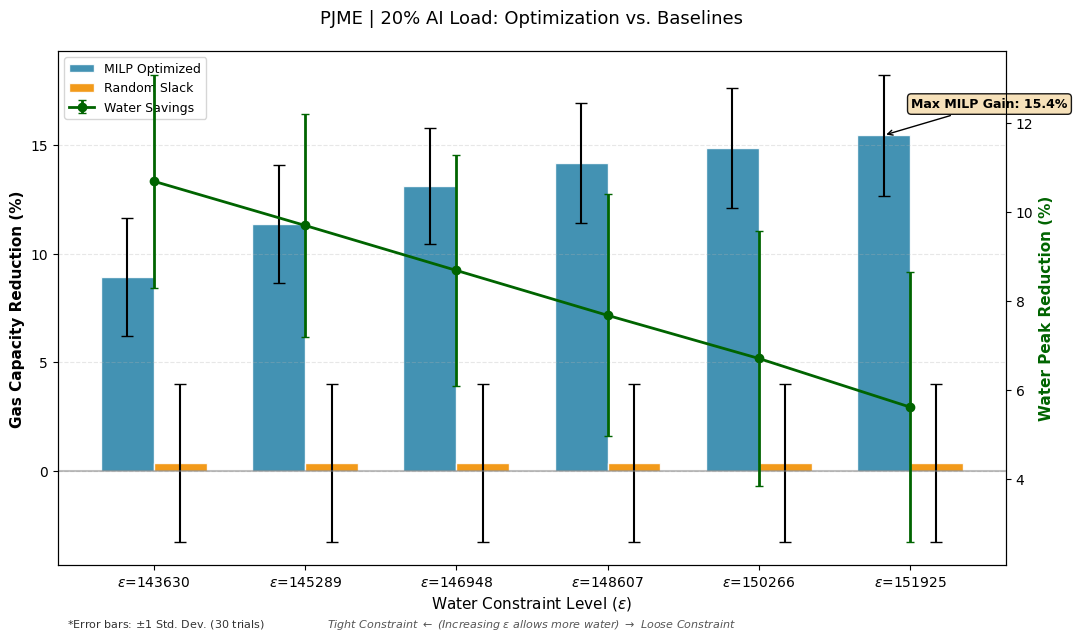

In [ ]:
# @title 9A. AI flexibility vs. baselines across water constraints - alternate for 9
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

def plot_flexibility_benefits_final(df: pd.DataFrame, region: str = "PJME", ai_frac: float = 0.2) -> Tuple[plt.Figure, plt.Axes]:
    # === 1. DATA PREPARATION ===
    work_df = df.copy()
    work_df["region"] = work_df["region"].astype(str).str.strip()

    cols = ["ai_fraction", "eps_idx", "epsilon_water_cap", "gas_improve_pct_vs_noflex",
            "water_improve_pct_vs_noflex", "gas_no_flex_mw", "gas_random_mw"]
    for col in cols:
        work_df[col] = pd.to_numeric(work_df[col], errors='coerce')

    filtered = work_df[
        (work_df["region"] == region) &
        np.isclose(work_df["ai_fraction"], ai_frac, atol=1e-8)
    ].dropna(subset=['eps_idx', 'gas_improve_pct_vs_noflex'])

    # MILP Stats
    milp_stats = filtered.groupby('eps_idx').agg({
        'epsilon_water_cap': 'mean',
        'gas_improve_pct_vs_noflex': ['mean', 'std'],
        'water_improve_pct_vs_noflex': ['mean', 'std']
    }).reset_index()
    milp_stats.columns = ['eps_idx', 'eps_mean', 'gas_mean', 'gas_std', 'water_mean', 'water_std']

    # Random Baseline calculation
    trial_baselines = filtered.groupby('trial')[['gas_no_flex_mw', 'gas_random_mw']].first().dropna()
    random_pct = 100 * (trial_baselines['gas_no_flex_mw'] - trial_baselines['gas_random_mw']) / trial_baselines['gas_no_flex_mw']
    r_mean, r_std = random_pct.mean(), random_pct.std()

    # === 2. PLOTTING ===
    fig, ax1 = plt.subplots(figsize=(11, 6.5))
    x = np.arange(len(milp_stats))
    width = 0.35

    # Gas Capacity Bars (Primary Axis)
    ax1.bar(x - width/2, milp_stats['gas_mean'], width, yerr=milp_stats['gas_std'],
            label='MILP Optimized', color='#2E86AB', alpha=0.9, capsize=4, edgecolor='white')

    # Explicitly showing Random Slack
    ax1.bar(x + width/2, [r_mean]*len(x), width, yerr=[r_std]*len(x),
            label='Random Slack', color='#F18F01', alpha=0.9, capsize=4, edgecolor='white')

    # Water Reduction Line (Secondary Axis)
    ax2 = ax1.twinx()
    ax2.errorbar(x, milp_stats['water_mean'], yerr=milp_stats['water_std'],
                 fmt='o-', color='#006400', linewidth=2, markersize=6, capsize=3, label='Water Savings')

    # === 3. FORMATTING & COMMENTARY ===
    ax1.axhline(0, color='gray', lw=1.5, alpha=0.5)
    ax1.set_ylabel('Gas Capacity Reduction (%)', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Water Peak Reduction (%)', fontsize=11, fontweight='bold', color='#006400')

    # Fix X-Axis labels using Raw Strings (r"") to avoid SyntaxWarnings
    labels = [rf"$\epsilon$={int(m)}" for m in milp_stats['eps_mean']]
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels)
    ax1.set_xlabel(r'Water Constraint Level ($\epsilon$)', fontsize=11)

    # X-axis commentary
    ax1.text(0.5, -0.12, r"Tight Constraint $\leftarrow$ (Increasing $\epsilon$ allows more water) $\rightarrow$ Loose Constraint",
             transform=ax1.transAxes, ha='center', fontsize=8, color='#555555', fontstyle='italic')

    # Error bar note
    ax1.text(0.01, -0.12, "*Error bars: $\pm$1 Std. Dev. (30 trials)",
             transform=ax1.transAxes, fontsize=8, alpha=0.8)

    # Fixed Yellow Label - positioned relative to the plot area to prevent "haywire" movement
    ax1.annotate(f'Max MILP Gain: {milp_stats["gas_mean"].max():.1f}%',
                 xy=(x[np.argmax(milp_stats['gas_mean'])] - width/2, milp_stats['gas_mean'].max()),
                 xytext=(20, 20), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black', lw=1),
                 bbox=dict(boxstyle='round,pad=0.3', fc='wheat', alpha=0.9),
                 fontsize=9, fontweight='bold')

    ax1.set_title(f'{region} | {int(ai_frac*100)}% AI Load: Optimization vs. Baselines', fontsize=13, pad=20)
    ax1.grid(axis='y', linestyle='--', alpha=0.3)

    # Legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=9, frameon=True)

    plt.tight_layout()
    return fig, ax1

# usage: fig, ax = plot_flexibility_benefits_final(out)
fig, ax = plot_flexibility_benefits_final(out)


CAPTION:
Pareto frontier of gas capacity vs. water peak for PJME 20% AI load. Each blue point is an ε-constrained MILP schedule (mean across trials); red X and orange square are no-flex and random-contiguous baselines. The curve shows the trade-off between reducing gas capacity and limiting peak water impact under grid stress.


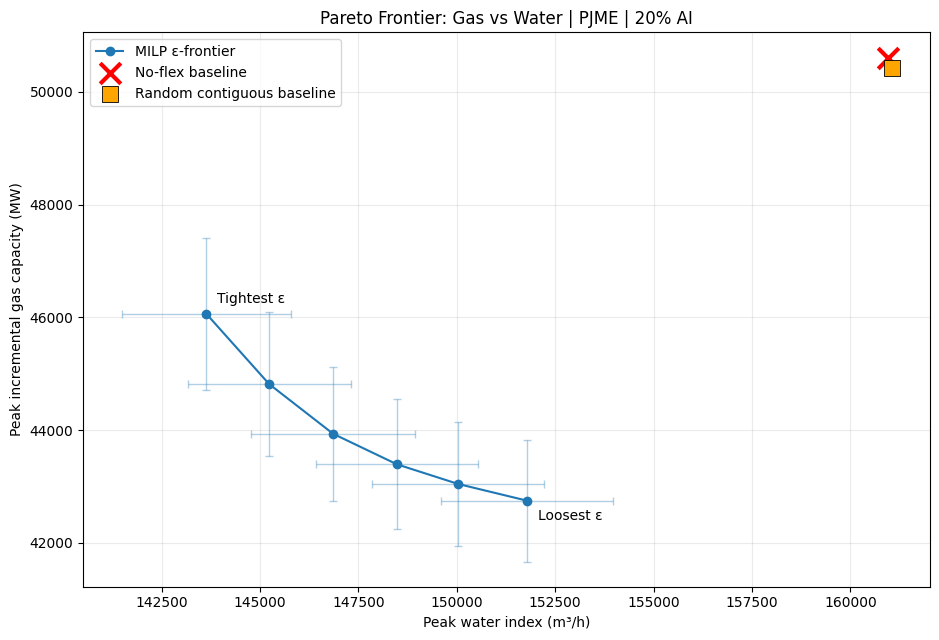

In [ ]:
# @title 10. Pareto frontier of gas capacity vs. water peak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_pareto_frontier_with_baselines(
    out: pd.DataFrame,
    region: str = "COMED",
    ai_frac: float = 0.10,
    sort_by: str = "eps_idx",          # "eps_idx" or "epsilon_water_cap"
    show_errorbars: bool = True,
):
    """
    Pareto Frontier With Baselines (ISEF-style)

    X-axis: water_peak_m3h_mean (m^3/h)  -> computed as mean water_peak_m3h across trials per eps point
    Y-axis: gas_peak_mw_mean (MW)        -> computed as mean gas_peak_mw across trials per eps point

    Baselines (computed across trials; pulled once per trial):
      - No-flex: red X
      - Random contiguous: orange square
      - MILP frontier: blue circles + line (ordered by eps_idx or epsilon cap)

    Requires `out` to contain at least:
      region, ai_fraction, trial, eps_idx, epsilon_water_cap,
      gas_peak_mw, water_peak_m3h,
      gas_no_flex_mw, water_no_flex_m3h,
      gas_random_mw, water_random_m3h
    """
    df = out.copy()

    # --- robust filtering ---
    df["region"] = df["region"].astype(str).str.strip()
    df["ai_fraction"] = pd.to_numeric(df["ai_fraction"], errors="coerce")
    df["trial"] = pd.to_numeric(df["trial"], errors="coerce")

    df = df[(df["region"] == str(region)) & (np.isclose(df["ai_fraction"], float(ai_frac), atol=1e-9))]
    if df.empty:
        raise ValueError(f"No rows found for region={region} and ai_frac={ai_frac}")

    # Ensure numeric
    num_cols = [
        "eps_idx","epsilon_water_cap","gas_peak_mw","water_peak_m3h",
        "gas_no_flex_mw","water_no_flex_m3h","gas_random_mw","water_random_m3h"
    ]
    for c in num_cols:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(subset=["eps_idx","epsilon_water_cap","gas_peak_mw","water_peak_m3h","trial"])
    if df.empty:
        raise ValueError("After numeric cleanup, no valid MILP rows remain.")

    # --- frontier stats across trials for each eps point ---
    frontier = (
        df.groupby("eps_idx", as_index=False)
          .agg(
              epsilon_mean=("epsilon_water_cap","mean"),
              water_mean=("water_peak_m3h","mean"),
              water_std =("water_peak_m3h","std"),
              gas_mean  =("gas_peak_mw","mean"),
              gas_std   =("gas_peak_mw","std"),
              n_trials  =("trial","nunique"),
          )
    )

    if sort_by == "epsilon_water_cap":
        frontier = frontier.sort_values("epsilon_mean")
    else:
        frontier = frontier.sort_values("eps_idx")

    # --- baselines across trials (grab one row per trial; baseline columns constant within trial) ---
    per_trial = (
        df.sort_values("eps_idx")
          .groupby("trial", as_index=False)
          .first()
          .dropna(subset=["gas_no_flex_mw","water_no_flex_m3h","gas_random_mw","water_random_m3h"])
    )

    noflex_gas   = per_trial["gas_no_flex_mw"].mean()
    noflex_water = per_trial["water_no_flex_m3h"].mean()
    rand_gas     = per_trial["gas_random_mw"].mean()
    rand_water   = per_trial["water_random_m3h"].mean()

    # --- plot ---
    fig, ax = plt.subplots(figsize=(9.5, 6.5))

    # MILP frontier (blue circles + line)
    ax.plot(
        frontier["water_mean"], frontier["gas_mean"],
        "-o", color="tab:blue", markerfacecolor="tab:blue",
        label="MILP ε-frontier"
    )

    # Optional error bars (mean ± std across trials)
    if show_errorbars:
        ax.errorbar(
            frontier["water_mean"], frontier["gas_mean"],
            xerr=frontier["water_std"], yerr=frontier["gas_std"],
            fmt="none", ecolor="tab:blue", alpha=0.35, capsize=3, linewidth=1
        )

    # Baselines
    ax.scatter(
        [noflex_water], [noflex_gas],
        marker="x", s=220, linewidths=3, color="red",
        label="No-flex baseline"
    )
    ax.scatter(
        [rand_water], [rand_gas],
        marker="s", s=140, color="orange", edgecolor="black", linewidth=0.6,
        label="Random contiguous baseline"
    )

    # Labels/title
    ax.set_xlabel("Peak water index (m³/h)")
    ax.set_ylabel("Peak incremental gas capacity (MW)")
    ax.set_title(f"Pareto Frontier: Gas vs Water | {region.upper()} | {int(ai_frac*100)}% AI")

    ax.grid(True, alpha=0.25)
    ax.legend(loc="best", frameon=True)

    # Helpful annotations (tightest & loosest points)
    first = frontier.iloc[0]
    last  = frontier.iloc[-1]
    ax.annotate("Tightest ε", (first["water_mean"], first["gas_mean"]),
                textcoords="offset points", xytext=(8, 8), fontsize=10)
    ax.annotate("Loosest ε", (last["water_mean"], last["gas_mean"]),
                textcoords="offset points", xytext=(8, -14), fontsize=10)

    # Caption/story (optional: print it so you can paste into poster)
    caption = (
        f"Pareto frontier of gas capacity vs. water peak for {region.upper()} {int(ai_frac*100)}% AI load. "
        f"Each blue point is an ε-constrained MILP schedule (mean across trials); red X and orange square are "
        f"no-flex and random-contiguous baselines. The curve shows the trade-off between reducing gas capacity "
        f"and limiting peak water impact under grid stress."
    )
    print("\nCAPTION:\n" + caption)

    plt.tight_layout()
    return fig, ax, frontier


# --- usage ---
fig, ax, frontier = plot_pareto_frontier_with_baselines(out, region="PJME", ai_frac=0.20)
plt.show()



CAPTION:
48-hour load profile for COMED 10% AI. Red: if AI jobs run as soon as they are ready (no flexibility), the peak increases. Blue: ε-constrained MILP shifts deferrable work into shoulder hours, shaving the peak while keeping energy similar. Green shading marks highest water-intensity hours (top 20%).


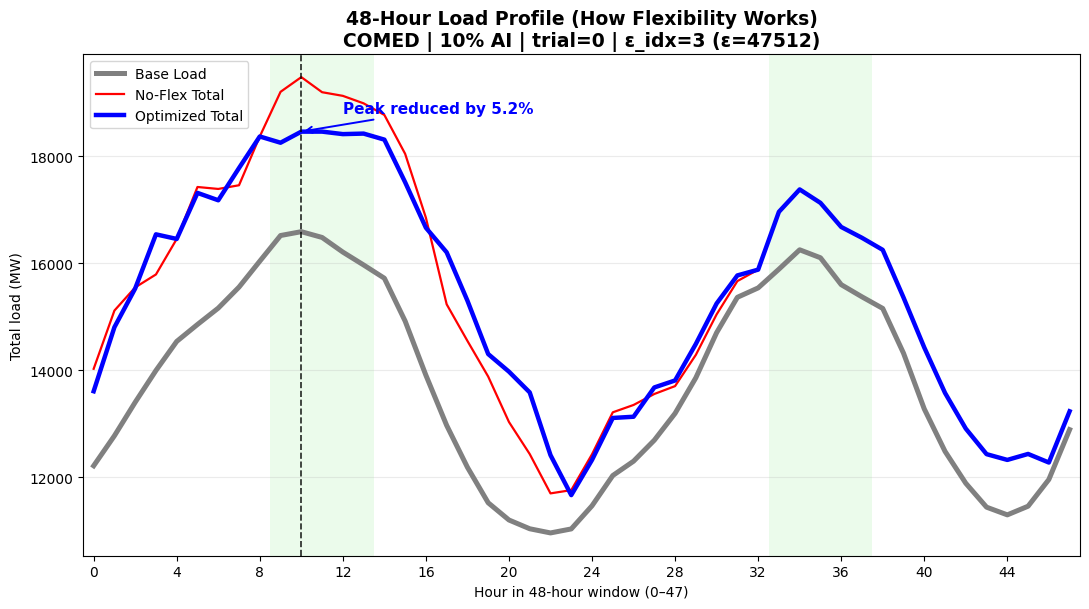

In [ ]:
# @title 11. Flexibility Chart
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_48h_load_profile_from_saved_files(
    BASE_DIR: str,
    out: pd.DataFrame,
    *,
    region: str = "COMED",
    ai_frac: float = 0.10,        # total AI level stored in out["ai_fraction"]
    trial: int = 0,
    eps_pick: str = "mid",        # "tight" (low eps_idx), "mid", "loose" (high eps_idx)
    eps_idx: int | None = None,   # override eps_pick if provided
    water_top_frac: float = 0.20  # shade top 20% water-intensity hours
):
    WINDOWS_PATH = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    WORKLOADS_PATH = os.path.join(BASE_DIR, "precalculated_workloads.csv")

    if not os.path.exists(WINDOWS_PATH) or not os.path.exists(WORKLOADS_PATH):
        raise FileNotFoundError(
            "Missing inputs for 48h profile. You need BOTH:\n"
            f"  - {WINDOWS_PATH}\n"
            f"  - {WORKLOADS_PATH}\n"
            "These are created by your Phase 1/2 precalc cells (run_window_precalc + run_workload_precalc)."
        )

    windows_df = pd.read_csv(WINDOWS_PATH)
    workloads_df = pd.read_csv(WORKLOADS_PATH)

    # --- window for region ---
    wdf = windows_df.copy()
    wdf["region"] = wdf["region"].astype(str).str.strip()
    wdf = wdf[wdf["region"] == str(region)].copy()
    if wdf.empty:
        raise ValueError(f"No window found for region={region} in {WINDOWS_PATH}")

    wdf["hour_idx"] = pd.to_numeric(wdf["hour_idx"], errors="coerce")
    wdf = wdf.sort_values("hour_idx")
    L_base = pd.to_numeric(wdf["L_base_MW"], errors="coerce").to_numpy(dtype=float)
    w_vec  = pd.to_numeric(wdf["water_m3_per_mwh"], errors="coerce").to_numpy(dtype=float)
    if not np.isfinite(L_base).all() or not np.isfinite(w_vec).all():
        raise ValueError("Non-finite values in L_base or w_vec (check cleaned_regional_windows.csv).")

    T = int(len(L_base))
    L_max = float(np.max(L_base))

    # --- jobs for scenario ---
    jdf = workloads_df.copy()
    jdf["region"] = jdf["region"].astype(str).str.strip()
    jdf["ai_fraction"] = pd.to_numeric(jdf["ai_fraction"], errors="coerce")
    jdf["trial"] = pd.to_numeric(jdf["trial"], errors="coerce")

    jobs_rows = jdf[
        (jdf["region"] == str(region)) &
        (np.isclose(jdf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (jdf["trial"].astype(int) == int(trial))
    ].copy()
    if jobs_rows.empty:
        raise ValueError(f"No jobs found for region={region}, ai_frac={ai_frac}, trial={trial} in {WORKLOADS_PATH}")

    jobs = jobs_rows[["id","p","d","r","e"]].to_dict("records")

    # --- reconstruct SAME seed logic used in your Cell 6 ---
    # Prefer your original REGIONS / AI_LOAD_LEVELS ordering if present (best match).
    unique_regions = list(jdf["region"].dropna().astype(str).unique())
    unique_ai = sorted(list(jdf["ai_fraction"].dropna().astype(float).unique()))

    try:
        region_to_i = {str(r): i for i, r in enumerate(REGIONS)}  # noqa: F821
    except Exception:
        region_to_i = {r: i for i, r in enumerate(unique_regions)}

    try:
        ai_levels = [float(a) for a in AI_LOAD_LEVELS]            # noqa: F821
        ai_to_i = {a: i for i, a in enumerate(ai_levels)}
    except Exception:
        ai_to_i = {a: i for i, a in enumerate(unique_ai)}

    # Handle float match for ai_frac
    if float(ai_frac) not in ai_to_i:
        closest = min(ai_to_i.keys(), key=lambda x: abs(x - float(ai_frac)))
        if abs(closest - float(ai_frac)) > 1e-6:
            raise ValueError(f"ai_frac={ai_frac} not found in AI levels; nearest is {closest}")
        ai_key = closest
    else:
        ai_key = float(ai_frac)

    if str(region) not in region_to_i:
        raise ValueError(f"region={region} not found in region index mapping.")

    seed = int(int(trial) + 10_000*region_to_i[str(region)] + 1_000_000*ai_to_i[ai_key])
    rng = np.random.default_rng(seed)

    # Online AI portion (your calibration)
    ai_online_portion = 0.5 * float(ai_frac)
    L_online = build_online_ai_load(wdf, L_max, ai_online_portion, rng)  # must exist
    L_online = np.asarray(L_online, dtype=float)
    if len(L_online) != T or not np.isfinite(L_online).all():
        raise ValueError("Bad L_online generated.")

    # --- pick ε point from out (for this region/ai/trial) ---
    odf = out.copy()
    odf["region"] = odf["region"].astype(str).str.strip()
    odf["ai_fraction"] = pd.to_numeric(odf["ai_fraction"], errors="coerce")
    odf["trial"] = pd.to_numeric(odf["trial"], errors="coerce")
    odf["eps_idx"] = pd.to_numeric(odf["eps_idx"], errors="coerce")
    odf["epsilon_water_cap"] = pd.to_numeric(odf["epsilon_water_cap"], errors="coerce")

    sub = odf[
        (odf["region"] == str(region)) &
        (np.isclose(odf["ai_fraction"], float(ai_frac), atol=1e-9)) &
        (odf["trial"].astype(int) == int(trial))
    ].dropna(subset=["eps_idx","epsilon_water_cap"]).copy()

    if sub.empty:
        raise ValueError("No ε results found in `out` for this region/ai/trial.")

    sub = sub.sort_values("eps_idx")
    if eps_idx is None:
        if eps_pick == "tight":
            eps_idx = int(sub["eps_idx"].iloc[0])
        elif eps_pick == "loose":
            eps_idx = int(sub["eps_idx"].iloc[-1])
        else:
            eps_idx = int(sub["eps_idx"].iloc[len(sub)//2])

    row = sub[sub["eps_idx"].astype(int) == int(eps_idx)]
    if row.empty:
        raise ValueError(f"eps_idx={eps_idx} not available for this trial. Have: {sorted(sub['eps_idx'].unique())}")

    water_epsilon = float(row["epsilon_water_cap"].iloc[0])

    # --- schedules ---
    def_no = schedule_no_flex(jobs, T)  # must exist
    L_no = L_base + L_online + def_no

    sol = solve_milp_with_schedule(
        L_base=L_base,
        L_online=L_online,
        jobs=jobs,
        w_vec=w_vec,
        alpha=STRESS_ALPHA,            # must exist
        rho=RHO,                       # must exist
        import_limit_MW=IMPORT_LIMIT_MW,# must exist
        mode="epsilon",
        water_epsilon=water_epsilon
    )
    # if sol["status"] not in ("Optimal", "Not Solved"):
    #     raise RuntimeError(f"MILP status={sol['status']} (not usable).")

    # def_opt = np.asarray(sol["deferr_mw"], dtype=float)

    if not sol.get("has_solution", False):
        raise RuntimeError(f"MILP produced no readable solution (status={sol.get('status')}).")

    def_opt = np.asarray(sol.get("deferr_mw", np.full(T, np.nan)), dtype=float)
    if not np.isfinite(def_opt).all():
        raise RuntimeError(f"MILP returned non-finite schedule (status={sol.get('status')}).")

    L_opt = L_base + L_online + def_opt

    # --- cues ---
    peak_t = int(np.argmax(L_no))
    peak_no = float(np.max(L_no))
    peak_opt = float(np.max(L_opt))
    peak_reduction_pct = 100.0 * (peak_no - peak_opt) / max(peak_no, 1e-9)

    # water shading (top X%)
    thr = float(np.quantile(w_vec, 1.0 - float(water_top_frac)))
    high_water = (w_vec >= thr)

    # --- plot ---
    x = np.arange(T)
    fig, ax = plt.subplots(figsize=(11, 6.2))

    # Shade high-water hours
    for t in range(T):
        if high_water[t]:
            ax.axvspan(t - 0.5, t + 0.5, color="#c7f5c7", alpha=0.35, linewidth=0)

    ax.plot(x, L_base, color="gray", linewidth=3.6, label="Base Load")
    ax.plot(x, L_no,   color="red",  linewidth=1.6, label="No-Flex Total")
    ax.plot(x, L_opt,  color="blue", linewidth=3.2, label="Optimized Total")

    # peak marker based on no-flex
    ax.axvline(peak_t, color="black", linestyle="--", linewidth=1.2, alpha=0.85)

    ax.annotate(
        f"Peak reduced by {peak_reduction_pct:.1f}%",
        xy=(peak_t, peak_opt),
        xytext=(min(T-1, peak_t + 2), peak_opt + 0.04*(peak_no - np.min(L_base) + 1)),
        arrowprops=dict(arrowstyle="->", color="blue", lw=1.4),
        fontsize=11, fontweight="bold", color="blue"
    )

    ax.set_xlim(-0.5, T - 0.5)
    ax.set_xticks(np.arange(0, T, 4))
    ax.set_xlabel("Hour in 48-hour window (0–47)")
    ax.set_ylabel("Total load (MW)")
    ax.grid(True, axis="y", alpha=0.25)

    ax.set_title(
        f"48-Hour Load Profile (How Flexibility Works)\n"
        f"{region.upper()} | {int(ai_frac*100)}% AI | trial={trial} | ε_idx={eps_idx} (ε={water_epsilon:.0f})",
        fontsize=13.5, fontweight="bold"
    )

    ax.legend(loc="upper left", frameon=True)
    plt.tight_layout()

    caption = (
        f"48-hour load profile for {region.upper()} {int(ai_frac*100)}% AI. "
        f"Red: if AI jobs run as soon as they are ready (no flexibility), the peak increases. "
        f"Blue: ε-constrained MILP shifts deferrable work into shoulder hours, shaving the peak while keeping energy similar. "
        f"Green shading marks highest water-intensity hours (top {int(water_top_frac*100)}%)."
    )
    print("\nCAPTION:\n" + caption)

    return fig, ax


# --- Usage (you already have out loaded) ---
fig, ax = plot_48h_load_profile_from_saved_files(
    BASE_DIR=BASE_DIR,
    out=out,
    region="COMED",
    ai_frac=0.10,
    trial=0,
    eps_pick="mid",   # or "tight" / "loose"
    water_top_frac=0.20
)
plt.show()


/tmp/ipython-input-2633155784.py:77: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["region", "ai_fraction", "water_level", "trial"], as_index=False)
/tmp/ipython-input-2633155784.py:83: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  per_trial.groupby(["region", "ai_fraction", "water_level"], as_index=False)


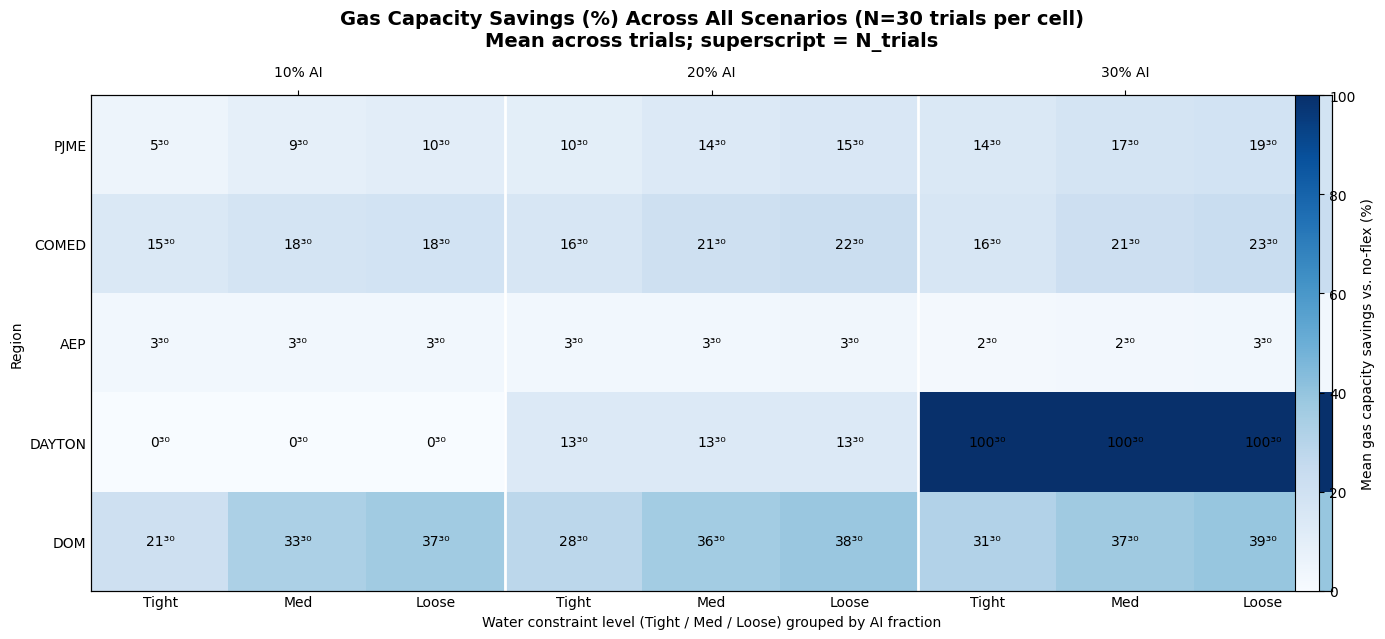

In [ ]:
# @title 12. Heatmap of Capacity Savings Across All Cases
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- helpers ----------
_SUP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
def to_superscript(n: int) -> str:
    """Unicode superscript digits, e.g., 15 -> ¹⁵"""
    return str(int(n)).translate(_SUP)

def add_water_level(out: pd.DataFrame) -> pd.DataFrame:
    """
    Adds a categorical 'water_level' in {Tight, Med, Loose}.
    Uses eps_frac if present; otherwise derives eps_frac from eps_idx within each (region, ai_fraction, trial).
    """
    df = out.copy()
    for c in ["ai_fraction", "eps_idx", "trial", "gas_improve_pct_vs_noflex"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # region string normalize
    if "region" in df.columns:
        df["region"] = df["region"].astype(str).str.strip()

    if "eps_frac" not in df.columns or df["eps_frac"].isna().all():
        # derive eps_frac per trial: eps_idx / max_eps_idx
        if "eps_idx" not in df.columns:
            raise ValueError("Need eps_frac or eps_idx in `out` to define Tight/Med/Loose.")
        g = df.groupby(["region", "ai_fraction", "trial"])["eps_idx"].transform("max")
        df["eps_frac"] = df["eps_idx"] / g.replace(0, np.nan)

    # Cut into thirds
    df["water_level"] = pd.cut(
        df["eps_frac"],
        bins=[-np.inf, 1/3, 2/3, np.inf],
        labels=["Tight", "Med", "Loose"]
    )
    return df


# ---------- main chart ----------
def heatmap_capacity_savings_all_cases(
    out: pd.DataFrame,
    regions_order=None,
    ai_order=None,
    title_extra: str = "",
    figsize=(14, 6.5)
):
    """
    Chart 4: Heatmap of Capacity Savings Across All Cases

    Rows: Regions
    Columns: AI Fraction grouped into 3 subcolumns (Tight/Med/Loose)
    Color: mean gas capacity savings % vs no-flex
    Cell text: mean savings (rounded) + superscript N_trials (unique trials)
    """

    df = add_water_level(out)

    # keep only what we need
    needed = ["region", "ai_fraction", "trial", "water_level", "gas_improve_pct_vs_noflex"]
    missing = [c for c in needed if c not in df.columns]
    if missing:
        raise ValueError(f"`out` missing columns: {missing}")

    df = df.dropna(subset=["region", "ai_fraction", "trial", "water_level", "gas_improve_pct_vs_noflex"]).copy()

    # Order controls
    if regions_order is None:
        regions_order = list(df["region"].unique())
    if ai_order is None:
        ai_order = sorted(df["ai_fraction"].unique())

    # --- aggregate correctly (avoid overweighting ε points) ---
    # 1) per trial average within each water_level band
    per_trial = (
        df.groupby(["region", "ai_fraction", "water_level", "trial"], as_index=False)
          .agg(sav_mean=("gas_improve_pct_vs_noflex", "mean"))
    )

    # 2) across trials: mean savings, and N_trials
    agg = (
        per_trial.groupby(["region", "ai_fraction", "water_level"], as_index=False)
                 .agg(
                     savings_mean=("sav_mean", "mean"),
                     n_trials=("trial", "nunique")
                 )
    )

    # Build full grid of columns: (ai, water_level)
    levels = ["Tight", "Med", "Loose"]
    col_keys = [(a, lv) for a in ai_order for lv in levels]

    # Create matrix for imshow + annotation text
    nR = len(regions_order)
    nC = len(col_keys)

    Z = np.full((nR, nC), np.nan, dtype=float)
    N = np.zeros((nR, nC), dtype=int)

    # Fast lookup
    lookup = {(r, a, lv): (m, n) for r, a, lv, m, n in agg[["region","ai_fraction","water_level","savings_mean","n_trials"]].values}

    for i, r in enumerate(regions_order):
        for j, (a, lv) in enumerate(col_keys):
            key = (str(r), float(a), str(lv))
            if key in lookup:
                m, n = lookup[key]
                Z[i, j] = float(m)
                N[i, j] = int(n)

    # --- plot ---
    fig, ax = plt.subplots(figsize=figsize)

    # Use a blue scale; NaNs show as light gray
    cmap = plt.cm.Blues.copy()
    cmap.set_bad(color="lightgray")

    im = ax.imshow(np.ma.masked_invalid(Z), aspect="auto", cmap=cmap)

    # Row labels (regions)
    ax.set_yticks(np.arange(nR))
    ax.set_yticklabels(regions_order)

    # Bottom x labels: Tight/Med/Loose repeated
    ax.set_xticks(np.arange(nC))
    ax.set_xticklabels([lv for _a in ai_order for lv in levels], rotation=0)

    # Group separators between AI blocks
    for k in range(1, len(ai_order)):
        ax.axvline(k*3 - 0.5, color="white", linewidth=2)

    # Top axis for AI fraction group labels
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    centers = [k*3 + 1 for k in range(len(ai_order))]  # center of each 3-col block
    ax_top.set_xticks(centers)
    ax_top.set_xticklabels([f"{int(round(a*100))}% AI" for a in ai_order])
    ax_top.tick_params(axis="x", pad=8)

    # Cell annotations: "16¹⁵"
    for i in range(nR):
        for j in range(nC):
            if np.isfinite(Z[i, j]):
                txt = f"{Z[i,j]:.0f}{to_superscript(N[i,j])}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=10, color="black")

    # Title + colorbar
    avg_n = int(np.nanmax(N)) if np.nanmax(N) > 0 else 0
    title = "Gas Capacity Savings (%) Across All Scenarios"
    if avg_n:
        title += f" (N={avg_n} trials per cell)"
    if title_extra:
        title += f"\n{title_extra}"
    ax.set_title(title, fontsize=14, fontweight="bold", pad=14)

    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Mean gas capacity savings vs. no-flex (%)")

    # Clean look
    ax.set_xlabel("Water constraint level (Tight / Med / Loose) grouped by AI fraction")
    ax.set_ylabel("Region")
    ax.tick_params(axis="both", length=0)

    plt.tight_layout()
    return fig, ax


# --------- usage ----------
out_path = os.path.join(BASE_DIR, "final_results_epsilon_frontier.csv")
out = pd.read_csv(out_path)

#Optional: enforce a specific region order and AI list (edit as needed)
regions_order = ["PJME","COMED","AEP","DAYTON","DOM"]
ai_order = [0.05, 0.10, 0.20, 0.30]

fig, ax = heatmap_capacity_savings_all_cases(
    out,
    regions_order=None,   # or regions_order
    ai_order=None,        # or ai_order
    title_extra="Mean across trials; superscript = N_trials"
)
plt.show()
